In [1]:
# Install + Upload dataset
!pip install -q albumentations optuna einops timm fvcore huggingface_hub

import os, glob, zipfile
from google.colab import files

ROOT = "/content/data/IDRiD"
os.makedirs(ROOT, exist_ok=True)

print("Select your dataset zip (B__Disease_Grading.zip) ...")
uploaded = files.upload()
for fname in uploaded.keys():
    with zipfile.ZipFile(fname, "r") as z:
        z.extractall(ROOT)
    os.remove(fname)
    print("Extracted:", fname)

# ---- check
csvs = glob.glob(f"{ROOT}/**/*.csv", recursive=True)
imgs = glob.glob(f"{ROOT}/**/*.jpg", recursive=True)
print("CSV files:", *csvs, sep="\n  ")
print("Images:", len(imgs))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Select your dataset zip (B__Disease_Grading.zip) ...


Saving B. Disease Grading.zip to B. Disease Grading.zip
Extracted: B. Disease Grading.zip
CSV files:
  /content/data/IDRiD/B. Disease Grading/2. Groundtruths/b. IDRiD_Disease Grading_Testing Labels.csv
  /content/data/IDRiD/B. Disease Grading/2. Groundtruths/a. IDRiD_Disease Grading_Training Labels.csv
Images: 516


In [2]:
#  Locate dataset folders
import os, glob

ROOT = "/content/data/IDRiD"
csv_train = glob.glob(f"{ROOT}/**/*Training Labels*.csv", recursive=True)[0]
csv_test  = glob.glob(f"{ROOT}/**/*Testing Labels*.csv",  recursive=True)[0]
img_train_dir = [d for d in glob.glob(f"{ROOT}/**/a. Training Set", recursive=True) if "Original Images" in d][0]
img_test_dir  = [d for d in glob.glob(f"{ROOT}/**/b. Testing Set",  recursive=True) if "Original Images" in d][0]

print("Train CSV :", csv_train)
print("Test CSV  :", csv_test)
print("Train imgs:", img_train_dir, len(os.listdir(img_train_dir)))   # 413
print("Test imgs :", img_test_dir,  len(os.listdir(img_test_dir)))    # 103

Train CSV : /content/data/IDRiD/B. Disease Grading/2. Groundtruths/a. IDRiD_Disease Grading_Training Labels.csv
Test CSV  : /content/data/IDRiD/B. Disease Grading/2. Groundtruths/b. IDRiD_Disease Grading_Testing Labels.csv
Train imgs: /content/data/IDRiD/B. Disease Grading/1. Original Images/a. Training Set 413
Test imgs : /content/data/IDRiD/B. Disease Grading/1. Original Images/b. Testing Set 103


In [3]:
# Configuration + seed
import random, numpy as np, torch

class CFG:
    img_size      = 224
    val_fraction  = 0.20
    split_seed    = 42
    seed          = 42
    retina_thr    = 10
    feat_dim      = 512
    n_dr, n_dme   = 5, 3
    lr            = 1e-4
    batch_size    = 32
    weight_decay  = 1e-4
    dropout       = 0.30
    epochs        = 100
    lambda_dr     = 1.0
    lambda_dme    = 1.0
    ln_eps        = 1e-6
    drop_path     = 0.2
    num_workers   = 2

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_seed(CFG.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Device: cpu 


In [4]:
#  Labels + data splitting
import pandas as pd, hashlib
from sklearn.model_selection import train_test_split

def read_labels(csv_path, img_dir, part):
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    df = df[["Image name", "Retinopathy grade", "Risk of macular edema"]].dropna()   # drops empty extra columns
    df.columns = ["name", "dr", "dme"]
    df["name"] = df["name"].astype(str).str.strip()
    df[["dr", "dme"]] = df[["dr", "dme"]].astype(int)
    df["path"] = [glob.glob(os.path.join(img_dir, n + ".*"))[0] for n in df["name"]]
    df["part"] = part
    return df.reset_index(drop=True)

dev_df  = read_labels(csv_train, img_train_dir, "train")   # 413
test_df = read_labels(csv_test,  img_test_dir,  "test")    # 103

tr_idx, va_idx = train_test_split(np.arange(len(dev_df)), test_size=CFG.val_fraction,
                                  random_state=CFG.split_seed, shuffle=True)
train_df = dev_df.iloc[tr_idx].reset_index(drop=True)
val_df   = dev_df.iloc[va_idx].reset_index(drop=True)

def class_table(train, val, test):
    rows = {}
    for n, d in (("Training", train), ("Validation", val), ("Held-out Test", test)):
        r = {"Images": len(d)}
        r.update({f"DR {g}": int((d.dr == g).sum()) for g in range(5)})
        r.update({f"DME {g}": int((d.dme == g).sum()) for g in range(3)})
        rows[n] = r
    t = pd.DataFrame(rows).T; t.loc["Total"] = t.sum(); return t

table1 = class_table(train_df, val_df, test_df)
display(table1)

md5 = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()
dev_hashes = {md5(p) for p in dev_df.path}
print("Duplicate images between development and test:", sum(md5(p) in dev_hashes for p in test_df.path))

os.makedirs("/content/outputs", exist_ok=True)
for n, d in (("train", train_df), ("val", val_df), ("test", test_df)):
    d[["name", "dr", "dme"]].to_csv(f"/content/outputs/split_{n}.csv", index=False)
table1.to_csv("/content/outputs/table1_class_distribution.csv")

,Images,DR 0,DR 1,DR 2,DR 3,DR 4,DME 0,DME 1,DME 2
Training,330,111,13,108,58,40,144,32,154
Validation,83,23,7,28,16,9,33,9,41
Held-out Test,103,34,5,32,19,13,45,10,48
Total,516,168,25,168,93,62,222,51,243


Duplicate images between development and test: 1


In [5]:
import json, hashlib
ART = "/content/drive/MyDrive/DR_DME_outputs/artifacts"
os.makedirs(ART, exist_ok=True)

sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()

split = pd.concat([
    dev_df.iloc[tr_idx].assign(split="train", dev_row=tr_idx),
    dev_df.iloc[va_idx].assign(split="val",   dev_row=va_idx),
    test_df.assign(split="test", dev_row=-1),
])
split["file_sha256"] = [sha(p) for p in split.path]
split[["name","split","dev_row","dr","dme","file_sha256"]].to_csv(f"{ART}/split_assignment.csv", index=False)

json.dump({"split_seed": CFG.split_seed, "val_fraction": CFG.val_fraction,
           "train_idx": tr_idx.tolist(), "val_idx": va_idx.tolist(),
           "n_train": len(tr_idx), "n_val": len(va_idx), "n_test": len(test_df)},
          open(f"{ART}/split_indices.json", "w"), indent=1)

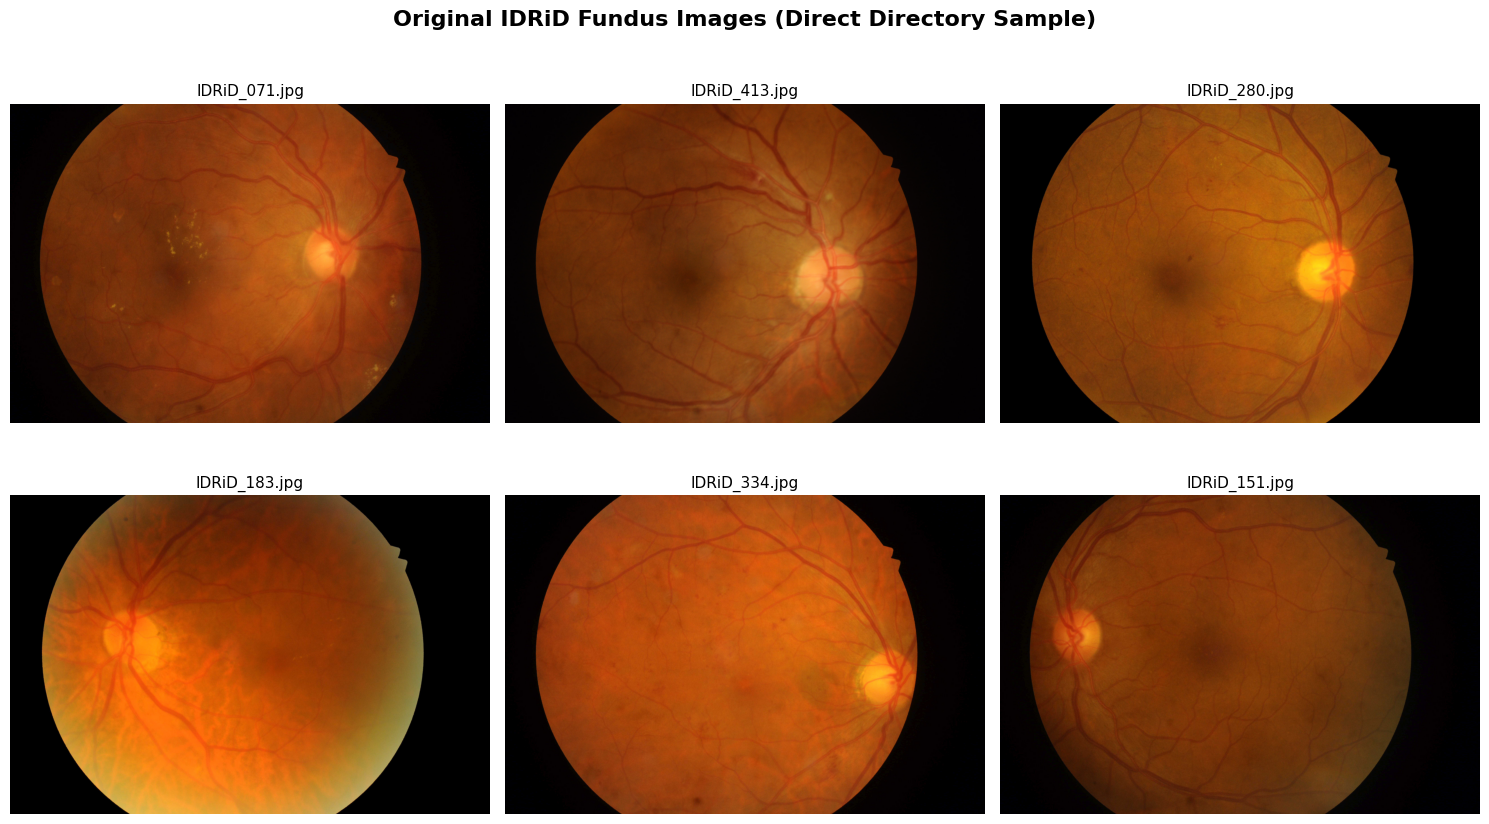

In [7]:
# ORIGINAL FUNDUS IMAGE INSPECTION
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

# Get list of all training images directly from the loaded directory
train_images = [os.path.join(img_train_dir, f) for f in os.listdir(img_train_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# Sample 6 images using a fixed seed for reproducibility
random.seed(123)
samples = random.sample(train_images, 6)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

axes = axes.flatten()

for ax, img_path in zip(axes, samples):
    image = Image.open(img_path).convert("RGB")
    ax.imshow(image)
    ax.set_title(os.path.basename(img_path), fontsize=11)
    ax.axis("off")

plt.suptitle(
    "Original IDRiD Fundus Images (Direct Directory Sample)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Preprocessing

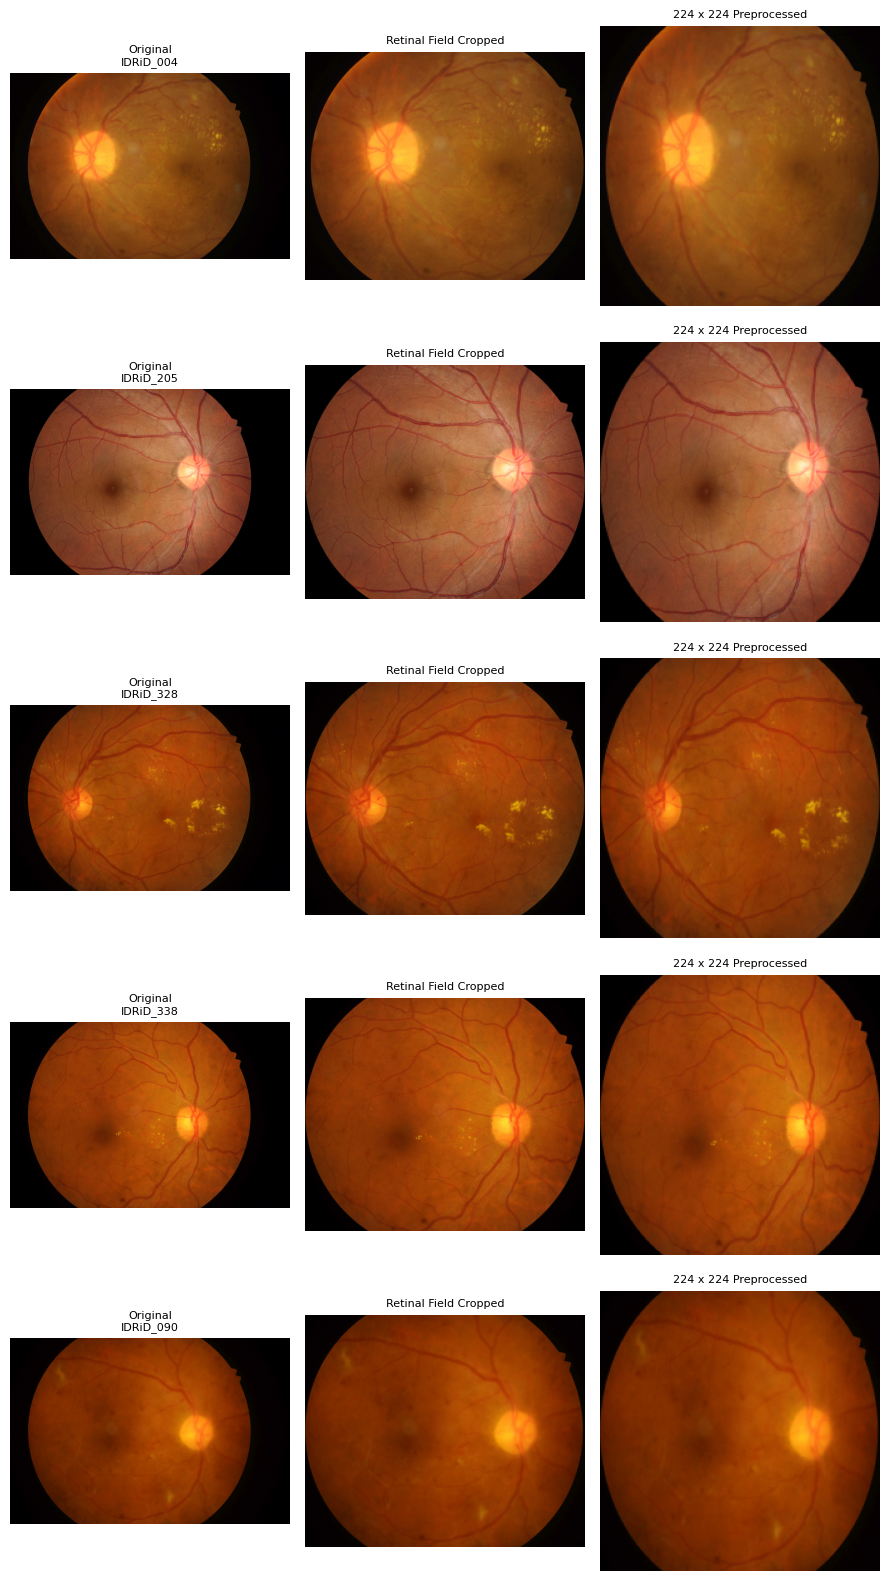

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def retina_bbox(rgb, thr=CFG.retina_thr):
    mask = (rgb.max(axis=2) > thr).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        h, w = mask.shape
        return 0, 0, w, h
    return cv2.boundingRect(max(cnts, key=cv2.contourArea))


def preprocess_steps(path, size=CFG.img_size):
    """Return (original, cropped, resized) for one image."""
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise FileNotFoundError(f"Could not read: {path}")
    raw = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    x, y, w, h = retina_bbox(raw)
    crop = raw[y:y + h, x:x + w]
    resized = cv2.resize(crop, (size, size), interpolation=cv2.INTER_AREA)
    return raw, crop, resized


def show_preprocessing_grid(paths, size=CFG.img_size, save_path=None):
    n = len(paths)
    fig, axes = plt.subplots(n, 3, figsize=(9, 3.2 * n))
    axes = np.atleast_2d(axes)  # handles n == 1

    col_titles = ["Original", "Retinal Field Cropped", f"{size} x {size} Preprocessed"]

    for row, p in enumerate(paths):
        raw, crop, pre = preprocess_steps(p, size)
        name = Path(p).stem  # e.g. IDRiD_001
        images = [raw, crop, pre]

        for col, (im, t) in enumerate(zip(images, col_titles)):
            ax = axes[row, col]
            ax.imshow(im)
            ax.axis("off")
            # Column 0 gets the filename under "Original", like your reference
            ax.set_title(f"{t}\n{name}" if col == 0 else t, fontsize=8)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


# Pick 5 random samples (use a fixed seed so it's reproducible)
sample_paths = train_df.path.sample(5, random_state=42).tolist()
show_preprocessing_grid(sample_paths)

Training samples: 330
Validation samples: 83
Testing samples: 103


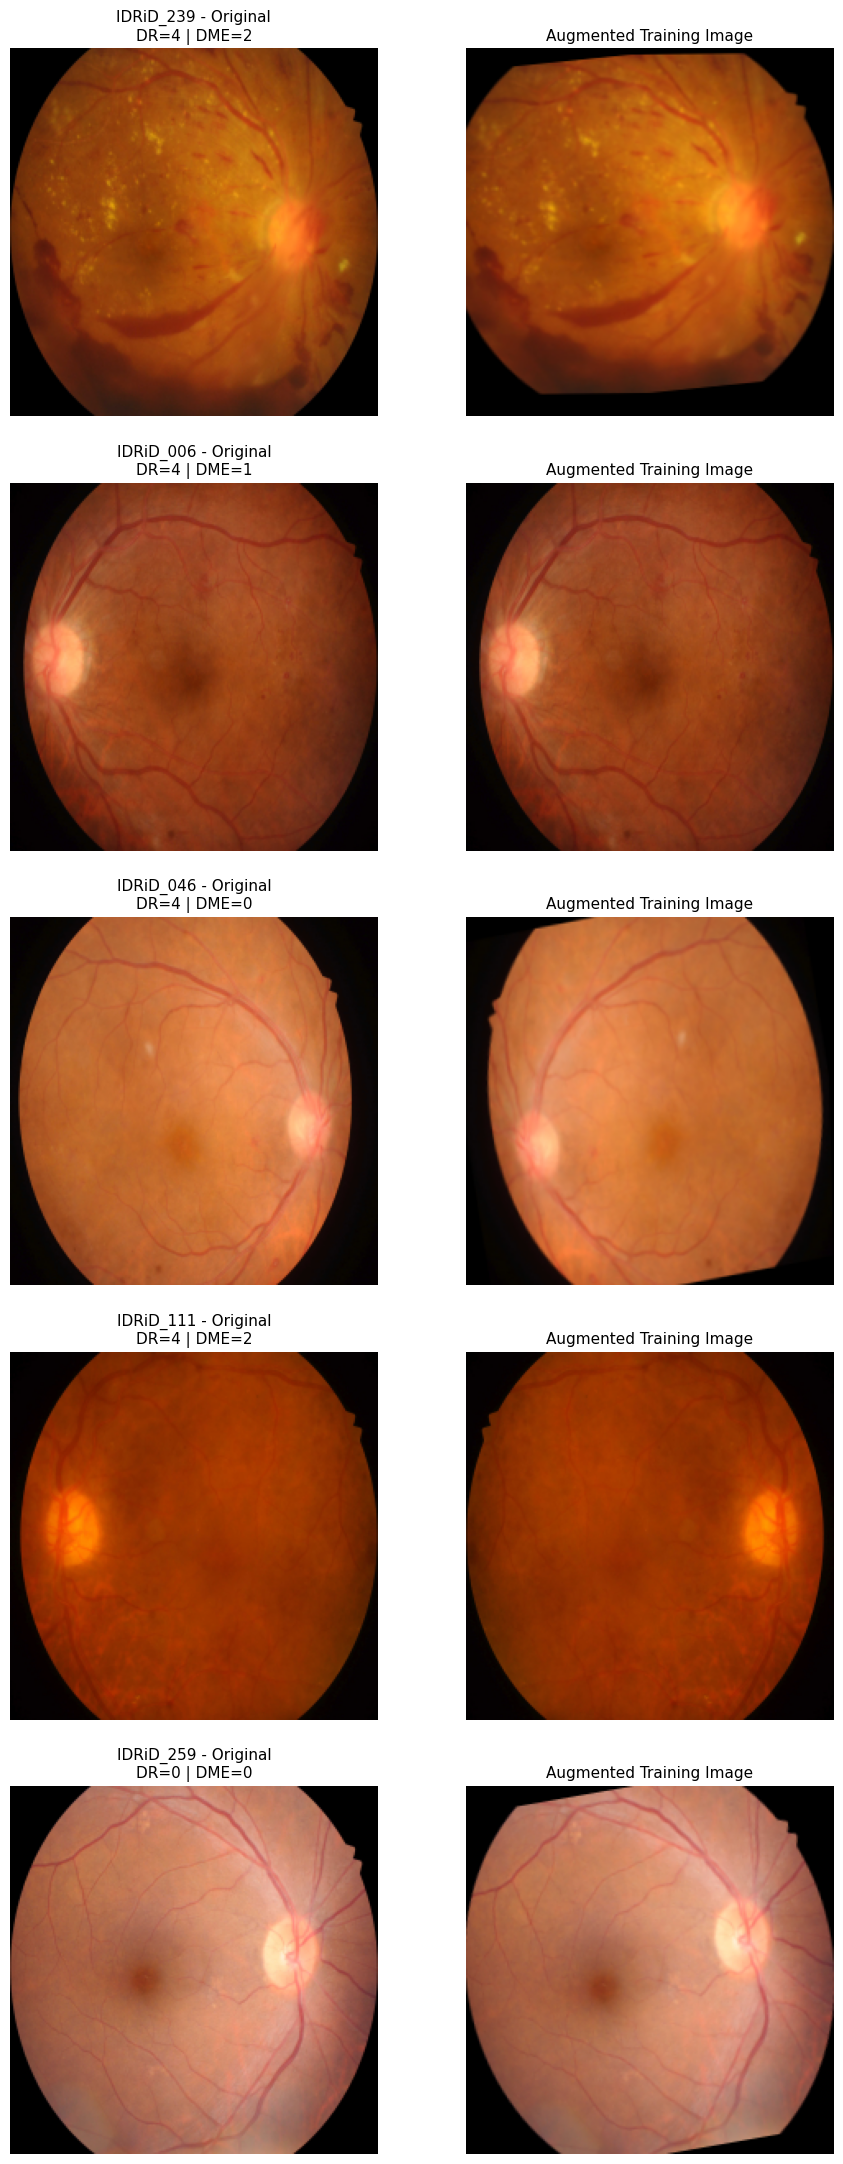

In [9]:
#  Augmentation + Dataset + Loaders

import albumentations as A
import torch
import numpy as np
import random
import cv2
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

train_aug = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.Rotate(
        limit=10,
        border_mode=cv2.BORDER_CONSTANT,
        p=0.5
    ),

    A.Affine(
        scale=(0.9, 1.1),
        translate_percent={
            "x": (-0.05, 0.05),
            "y": (-0.05, 0.05)
        },
        shear=(-3, 3),
        p=0.4
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.1,
        contrast_limit=0.1,
        p=0.4
    ),
])

# Helper wrapper to map to your defined preprocess_steps function
def load_and_preprocess(path):

    _, _, resized = preprocess_steps(path, size=CFG.img_size)
    return resized

class IDRiDGrading(Dataset):

    def __init__(self, df, aug=None):
        self.df = df.reset_index(drop=True)
        self.aug = aug

        self.cache = [
            load_and_preprocess(p)
            for p in self.df.path
        ]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):

        img = self.cache[i]

        if self.aug is not None:
            img = self.aug(image=img)["image"]

        x = torch.from_numpy(
            (img.astype(np.float32) / 255.0)
            .transpose(2, 0, 1)
            .copy()
        )

        return (
            x,
            int(self.df.dr[i]),
            int(self.df.dme[i]),
            self.df.name[i]
        )


def seed_worker(wid):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


train_ds = IDRiDGrading(train_df, aug=train_aug)
val_ds   = IDRiDGrading(val_df)
test_ds  = IDRiDGrading(test_df)


g = torch.Generator()
g.manual_seed(CFG.seed)

train_loader = DataLoader(
    train_ds,
    batch_size=CFG.batch_size,
    shuffle=True,
    num_workers=CFG.num_workers,
    worker_init_fn=seed_worker,
    generator=g,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=64,
    shuffle=False,
    num_workers=CFG.num_workers
)

test_loader = DataLoader(
    test_ds,
    batch_size=64,
    shuffle=False,
    num_workers=CFG.num_workers
)


print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Testing samples:", len(test_ds))


fig, ax = plt.subplots(5, 2, figsize=(10, 22))

for i in range(5):

    im = train_ds.cache[i]

    # Original image
    ax[i, 0].imshow(im)
    ax[i, 0].set_title(
        f"{train_df.name.iloc[i]} - Original\n"
        f"DR={train_df.dr.iloc[i]} | DME={train_df.dme.iloc[i]}",
        fontsize=11
    )
    ax[i, 0].axis("off")

    # Augmented image
    aug_img = train_aug(image=im)["image"]

    ax[i, 1].imshow(aug_img)
    ax[i, 1].set_title(
        "Augmented Training Image",
        fontsize=11
    )
    ax[i, 1].axis("off")


plt.tight_layout(pad=2.0)
plt.show()


In [10]:
import sys, platform, subprocess, importlib.metadata as md
pk = ["torch","torchvision","timm","numpy","pandas","scikit-learn","scipy","albumentations",
      "opencv-python","optuna","einops","huggingface_hub","matplotlib"]
env = {"python": sys.version, "platform": platform.platform(),
       "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       "packages": {p: md.version(p) for p in pk if md.distributions()}}
json.dump(env, open(f"{ART}/environment.json","w"), indent=1)
open(f"{ART}/requirements_frozen.txt","w").write(
    subprocess.run([sys.executable,"-m","pip","freeze"],capture_output=True,text=True).stdout)

json.dump({"CFG": {k:v for k,v in vars(CFG).items() if not k.startswith("_")},
           "preprocess": {"retina_thr": CFG.retina_thr, "img_size": CFG.img_size,
                          "resize": "INTER_AREA", "normalisation": "none (0-1 scaling)"},
           "augmentation": str(train_aug)},
          open(f"{ART}/config.json","w"), indent=1, default=str)

In [11]:
# Download ImageNet-pretrained EfficientVMamba-S weights
import os, glob, warnings, logging

# silence the Hugging Face "unauthenticated requests" warning and progress bars
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

from huggingface_hub import snapshot_download

WEIGHT_DIR = "/content/weights/evm_small"
ckpts = glob.glob(f"{WEIGHT_DIR}/**/*.ckpt", recursive=True)
if not ckpts:                                            # download only once
    snapshot_download("TerryPei/EfficientVMamba-Small", local_dir=WEIGHT_DIR)
    ckpts = glob.glob(f"{WEIGHT_DIR}/**/*.ckpt", recursive=True)

BACKBONE_CKPT = ckpts[0] if ckpts else None
if BACKBONE_CKPT:
    print(f"✅ ImageNet checkpoint ready: {BACKBONE_CKPT} ({os.path.getsize(BACKBONE_CKPT) / 1e6:.1f} MB)")
else:
    print("❌ Checkpoint not found - check the internet connection and re-run this cell")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

✅ ImageNet checkpoint ready: /content/weights/evm_small/efficient_vmamba_small.ckpt (45.3 MB)


In [ ]:
# EfficientVMamba-S backbone (no CUDA kernel needed)
import math, torch.nn as nn, torch.nn.functional as F
import torch.utils.checkpoint as cp
from collections import OrderedDict

USE_CHECKPOINT = True     # saves GPU memory during training (recomputes EVSS blocks in backward)

def selective_scan(u, delta, A, B, C, D, delta_bias, softplus=True):
    """Pure-PyTorch selective scan.
    u, delta: (b, K*d, L) | A: (K*d, N) | B, C: (b, K, N, L) | D: (K*d,)"""
    with torch.autocast(device_type="cuda", enabled=False):          # keep the scan in fp32
        u, delta, A, B, C, D, delta_bias = [t.float() for t in (u, delta, A, B, C, D, delta_bias)]
        b, KD, L = u.shape; K, N = B.shape[1], A.shape[1]; d = KD // K
        delta = delta + delta_bias[None, :, None]
        if softplus:
            delta = F.softplus(delta)
        Bt = B.permute(0, 1, 3, 2).unsqueeze(2)                       # b,K,1,L,N
        Ct = C.permute(0, 1, 3, 2)                                    # b,K,L,N
        dA  = torch.exp(delta.view(b, K, d, L, 1) * A.view(1, K, d, 1, N))   # b,K,d,L,N
        dBu = (delta * u).view(b, K, d, L, 1) * Bt                           # b,K,d,L,N
        h = u.new_zeros(b, K, d, N); hs = []
        for t in range(L):                                            # h_t = dA_t * h_{t-1} + dB_t u_t
            h = torch.addcmul(dBu[:, :, :, t], dA[:, :, :, t], h)
            hs.append(h)
        hs = torch.stack(hs, 3)                                       # b,K,d,L,N
        y = torch.einsum("bkdln,bkln->bkdl", hs, Ct).reshape(b, KD, L)
        return y + u * D[None, :, None]

print("Selective-scan backend: pure PyTorch (vectorised) + gradient checkpointing")


def efficient_scan(x, s=2):
    B, C, H, W = x.shape
    if H % s or W % s: x = F.pad(x, (0, (-W) % s, 0, (-H) % s))
    xt = x.transpose(2, 3)
    return torch.stack([x[:, :, ::s, ::s].reshape(B, C, -1), xt[:, :, ::s, 1::s].reshape(B, C, -1),
                        x[:, :, ::s, 1::s].reshape(B, C, -1), xt[:, :, 1::s, 1::s].reshape(B, C, -1)], 1)

def efficient_merge(ys, H0, W0, s=2):
    B, K, C, L = ys.shape; H, W = math.ceil(H0 / s), math.ceil(W0 / s)
    y = ys.new_zeros(B, C, H * s, W * s)
    y[:, :, ::s, ::s]   = ys[:, 0].reshape(B, C, H, W)
    y[:, :, 1::s, ::s]  = ys[:, 1].reshape(B, C, W, H).transpose(2, 3)
    y[:, :, ::s, 1::s]  = ys[:, 2].reshape(B, C, H, W)
    y[:, :, 1::s, 1::s] = ys[:, 3].reshape(B, C, W, H).transpose(2, 3)
    return y[:, :, :H0, :W0].reshape(B, C, -1)

class Permute(nn.Module):
    def __init__(self, *d): super().__init__(); self.d = d
    def forward(self, x): return x.permute(*self.d)

class DropPath(nn.Module):
    def __init__(self, p=0.): super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0: return x
        m = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(1 - self.p)
        return x * m / (1 - self.p)

class SS2D(nn.Module):
    def __init__(self, d_model, d_state=16, ssm_ratio=2.0, step=2):
        super().__init__()
        di = int(ssm_ratio * d_model); R = math.ceil(d_model / 16); N, K = d_state, 4
        self.R, self.N, self.K, self.step = R, N, K, step
        self.in_proj = nn.Linear(d_model, 2 * di, bias=False); self.act = nn.SiLU()
        self.conv2d = nn.Conv2d(di, di, 3, padding=1, groups=di)
        xw = torch.empty(K, R + 2 * N, di)
        for k in range(K): nn.init.kaiming_uniform_(xw[k], a=math.sqrt(5))
        self.x_proj_weight = nn.Parameter(xw)
        self.dt_projs_weight = nn.Parameter(torch.empty(K, di, R).uniform_(-R ** -0.5, R ** -0.5))
        dt = torch.exp(torch.rand(K, di) * (math.log(0.1) - math.log(0.001)) + math.log(0.001)).clamp(min=1e-4)
        self.dt_projs_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))
        self.A_logs = nn.Parameter(torch.log(torch.arange(1, N + 1, dtype=torch.float32).repeat(K * di, 1)))
        self.Ds = nn.Parameter(torch.ones(K * di))
        self.out_norm = nn.LayerNorm(di); self.out_proj = nn.Linear(di, d_model, bias=False)
    def forward(self, x):
        B, H, W, _ = x.shape
        x, z = self.in_proj(x).chunk(2, -1); z = self.act(z)
        x = self.act(self.conv2d(x.permute(0, 3, 1, 2).contiguous())); D = x.shape[1]
        xs = efficient_scan(x, self.step); L = xs.shape[-1]
        dts, Bs, Cs = torch.split(torch.einsum("bkdl,kcd->bkcl", xs, self.x_proj_weight), [self.R, self.N, self.N], 2)
        dts = torch.einsum("bkrl,kdr->bkdl", dts, self.dt_projs_weight)
        ys = selective_scan(xs.reshape(B, -1, L), dts.reshape(B, -1, L), -torch.exp(self.A_logs.float()),
                            Bs, Cs, self.Ds, self.dt_projs_bias.reshape(-1), True).reshape(B, 4, D, L)
        y = self.out_norm(efficient_merge(ys, H, W, self.step).transpose(1, 2)).reshape(B, H, W, D).to(z.dtype)
        return self.out_proj(y * z)

class BiAttn(nn.Module):
    def __init__(self, c, r=0.125):
        super().__init__()
        self.norm = nn.LayerNorm(c); self.global_reduce = nn.Linear(c, int(c * r))
        self.act_fn = nn.GELU(); self.channel_select = nn.Linear(int(c * r), c)
    def forward(self, x):
        g = self.norm(x).mean([1, 2], keepdim=True)
        return x * torch.sigmoid(self.channel_select(self.act_fn(self.global_reduce(g))))

class EVSSBlock(nn.Module):
    def __init__(self, dim, dp=0.):
        super().__init__()
        self.norm = nn.LayerNorm(dim); self.op = SS2D(dim)
        self.conv_branch = nn.Sequential(nn.Conv2d(dim, dim, 3, padding=1, groups=dim), nn.BatchNorm2d(dim),
                                         nn.GELU(), nn.Conv2d(dim, dim, 1))
        self.se = BiAttn(dim); self.drop_path = DropPath(dp)
    def _forward(self, inp):
        x = self.norm(inp)
        xc = self.conv_branch(x.permute(0, 3, 1, 2)).permute(0, 2, 3, 1)
        return inp + self.drop_path(self.se(self.op(x)) + self.se(xc))
    def forward(self, inp):
        if USE_CHECKPOINT and self.training and torch.is_grad_enabled():
            return cp.checkpoint(self._forward, inp, use_reentrant=False)
        return self._forward(inp)

class SqueezeExcite(nn.Module):
    def __init__(self, c, r):
        super().__init__()
        self.avgp = nn.AdaptiveAvgPool2d(1); self.conv_reduce = nn.Conv2d(c, r, 1)
        self.act_fn = nn.ReLU(inplace=True); self.conv_expand = nn.Conv2d(r, c, 1)
    def forward(self, x): return x * torch.sigmoid(self.conv_expand(self.act_fn(self.conv_reduce(self.avgp(x)))))

class InvertedResidual(nn.Module):           # Eq. (6)
    def __init__(self, c, e=4, se=0.125, dp=0.):
        super().__init__(); m = c * e
        self.conv_pw  = nn.Sequential(nn.Conv2d(c, m, 1, bias=False), nn.BatchNorm2d(m), nn.ReLU(inplace=True))
        self.conv_dw  = nn.Sequential(nn.Conv2d(m, m, 3, 1, 1, groups=m, bias=False), nn.BatchNorm2d(m), nn.ReLU(inplace=True))
        self.se       = SqueezeExcite(m, int(m * se))
        self.conv_pw2 = nn.Sequential(nn.Conv2d(m, c, 1, bias=False), nn.BatchNorm2d(c))
        self.drop = DropPath(dp)
    def forward(self, x): return x + self.drop(self.conv_pw2(self.se(self.conv_dw(self.conv_pw(x)))))

class PatchMerging2D(nn.Module):
    def __init__(self, d, od):
        super().__init__(); self.reduction = nn.Linear(4 * d, od, bias=False); self.norm = nn.LayerNorm(4 * d)
    def forward(self, x):
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], -1)
        return self.reduction(self.norm(x))

class EfficientVMambaS(nn.Module):
    """stem -> 2xEVSS@56x56x96 -> 2xEVSS@28x28x192 -> 4xInRes@14x14x384 -> 2xInRes@7x7x768"""
    def __init__(self, depths=(2, 2, 4, 2), dims=(64, 128, 256, 512), drop_path=0.2):
        super().__init__()
        self.patch_embed = nn.Sequential(nn.Conv2d(3, dims[0], 4, 4), Permute(0, 2, 3, 1), nn.LayerNorm(dims[0]))
        dpr = torch.linspace(0, drop_path, sum(depths)).tolist(); self.layers = nn.ModuleList()
        for i, dep in enumerate(depths):
            dp = dpr[sum(depths[:i]):sum(depths[:i + 1])]
            down = PatchMerging2D(dims[i], dims[i + 1]) if i < 3 else nn.Identity()
            if i < 2:
                self.layers.append(nn.Sequential(OrderedDict(
                    blocks=nn.Sequential(*[EVSSBlock(dims[i], dp[j]) for j in range(dep)]), downsample=down)))
            else:
                self.layers.append(nn.Sequential(Permute(0, 3, 1, 2),
                                                 *[InvertedResidual(dims[i], dp=dp[j]) for j in range(dep)],
                                                 Permute(0, 2, 3, 1), down))
        self.classifier = nn.Sequential(OrderedDict(norm=nn.LayerNorm(dims[-1])))
    def forward(self, x):
        x = self.patch_embed(x)
        for l in self.layers: x = l(x)
        return self.classifier.norm(x).permute(0, 3, 1, 2).contiguous()     # B,768,7,7

def load_imagenet_weights(model, path):
    if not path or not os.path.exists(path):
        print("WARNING: no ImageNet weights -> random init"); return model
    ck = torch.load(path, map_location="cpu", weights_only=False)
    sd = ck.get("model", ck.get("state_dict", ck))
    sd = {k.replace("module.", ""): v for k, v in sd.items()}
    own = model.state_dict()
    sd = {k: v for k, v in sd.items() if k in own and own[k].shape == v.shape}
    missing = model.load_state_dict(sd, strict=False).missing_keys
    print(f"Loaded {len(sd)} pretrained tensors, missing {len(missing)}")
    if missing: print("   first missing:", missing[:5])
    return model

# ---- quick test: shape, memory and speed of one training step
import time
bb = load_imagenet_weights(EfficientVMambaS(drop_path=CFG.drop_path), BACKBONE_CKPT).to(device).train()
torch.cuda.reset_peak_memory_stats()
x = torch.rand(CFG.batch_size, 3, 224, 224, device=device)
t0 = time.time()
with torch.autocast("cuda", dtype=torch.float16):
    f = bb(x)
f.float().mean().backward(); torch.cuda.synchronize()
print("Backbone output:", tuple(f.shape))                                    # (32, 768, 7, 7)
print(f"1 train step (batch {CFG.batch_size}): {time.time() - t0:.1f}s | peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
print(f"Backbone params: {sum(p.numel() for p in bb.parameters()) / 1e6:.2f} M")
del bb, x, f; torch.cuda.empty_cache()

Selective-scan backend: pure PyTorch (vectorised) + gradient checkpointing
Loaded 259 pretrained tensors, missing 0
Backbone output: (32, 512, 7, 7)
1 train step (batch 32): 60.7s | peak GPU memory 5.7 GB
Backbone params: 10.76 M


In [ ]:
# Proposed multi-task model
class TokenAttention(nn.Module):
    """Single-head attention, pre-LayerNorm, Q/K/V 768x768 with bias (Eqs. 10-11)."""
    def __init__(self, d=768, eps=1e-6):
        super().__init__()
        self.ln_q, self.ln_kv = nn.LayerNorm(d, eps=eps), nn.LayerNorm(d, eps=eps)
        self.q, self.k, self.v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.scale = 1 / math.sqrt(d)
    def forward(self, q_src, kv_src):
        q = self.q(self.ln_q(q_src)); kv = self.ln_kv(kv_src)
        w = torch.softmax(q @ self.k(kv).transpose(-2, -1) * self.scale, -1)   # B,49,49
        return w @ self.v(kv), w

class CoralHead(nn.Module):
    """p_k = sigmoid(w^T h + b_k): shared w, 4 threshold biases."""
    def __init__(self, d, n=5):
        super().__init__(); self.fc = nn.Linear(d, 1, bias=False); self.bias = nn.Parameter(torch.zeros(n - 1))
    def forward(self, h): return self.fc(h) + self.bias

class MultiTaskDRDME(nn.Module):
    def __init__(self, cfg=CFG, ckpt=None):
        super().__init__()
        D = cfg.feat_dim
        self.backbone = load_imagenet_weights(EfficientVMambaS(drop_path=cfg.drop_path), ckpt)
        self.proj_dr, self.proj_dme = nn.Linear(D, D), nn.Linear(D, D)
        self.att_dr  = TokenAttention(D, cfg.ln_eps)                          # DR  <- DME
        self.att_dme = TokenAttention(D, cfg.ln_eps)                          # DME <- DR
        self.drop = nn.Dropout(cfg.dropout)
        self.head_dr  = CoralHead(D, cfg.n_dr)
        self.head_dme = nn.Linear(D, cfg.n_dme)
        for n, m in self.named_modules():                                     # Xavier for new layers
            if not n.startswith("backbone") and isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, x, return_all=False):
        fmap = self.backbone(x)                                   # B,768,7,7
        Fs = fmap.flatten(2).transpose(1, 2)                      # B,49,768
        F_dr, F_dme = self.proj_dr(Fs), self.proj_dme(Fs)
        a_dr,  w_dr  = self.att_dr(F_dr, F_dme)
        a_dme, w_dme = self.att_dme(F_dme, F_dr)
        Fh_dr, Fh_dme = F_dr + a_dr, F_dme + a_dme
        out = {"dr_logits":  self.head_dr(self.drop(Fh_dr.mean(1))),
               "dme_logits": self.head_dme(self.drop(Fh_dme.mean(1)))}
        if return_all:
            out.update(fmap=fmap, tokens_dr=Fh_dr, tokens_dme=Fh_dme, attn_dr=w_dr, attn_dme=w_dme)
        return out

def coral_levels(y, n=5):
    return (y[:, None] > torch.arange(n - 1, device=y.device)[None]).float()

def dr_decode(logits):
    p = torch.sigmoid(logits)
    pred = (p > 0.5).sum(1)
    cum = torch.cat([torch.ones_like(p[:, :1]), p, torch.zeros_like(p[:, :1])], 1)
    probs = (cum[:, :-1] - cum[:, 1:]).clamp_min(0)
    return pred, probs / probs.sum(1, keepdim=True).clamp_min(1e-12)

def multitask_loss(out, y_dr, y_dme, cfg=CFG):
    l_dr = F.binary_cross_entropy_with_logits(out["dr_logits"].float(), coral_levels(y_dr),
                                              reduction="none").sum(1).mean()
    l_dme = F.cross_entropy(out["dme_logits"].float(), y_dme)
    return cfg.lambda_dr * l_dr + cfg.lambda_dme * l_dme, l_dr.item(), l_dme.item()

# ---- sanity check on one real batch
model = MultiTaskDRDME(CFG, BACKBONE_CKPT).to(device)
x, ydr, ydme, _ = next(iter(train_loader))
x, ydr, ydme = x.to(device), ydr.to(device), ydme.to(device)
out = model(x, return_all=True)
loss, ldr, ldme = multitask_loss(out, ydr, ydme)
loss.backward()
print({k: tuple(v.shape) for k, v in out.items()})
print(f"loss {loss.item():.4f} (DR {ldr:.4f}, DME {ldme:.4f})")
print(f"Total params: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")
model.zero_grad(set_to_none=True)

Loaded 259 pretrained tensors, missing 0
{'dr_logits': (32, 4), 'dme_logits': (32, 3), 'fmap': (32, 512, 7, 7), 'tokens_dr': (32, 49, 512), 'tokens_dme': (32, 49, 512), 'attn_dr': (32, 49, 49), 'attn_dme': (32, 49, 49)}
loss 4.7282 (DR 3.3794, DME 1.3488)
Total params: 12.87 M


In [ ]:
# Search settings + fitness
import os, json, time, math, numpy as np, pandas as pd, torch
from google.colab import drive
drive.mount("/content/drive")

SEARCH_DIR = "/content/drive/MyDrive/DR_DME_outputs/search"
os.makedirs(SEARCH_DIR, exist_ok=True)

# search space  encoded as [log10 lr, batch, log10 wd, dropout, epochs]
LOWER = np.array([-5.0,  8.0, -6.0, 0.1,  50.0])
UPPER = np.array([-3.0, 32.0, -3.0, 0.5, 150.0])
M_POP, T_ITERS = 10, 10            # 10 initial + 10 x 10 offspring = 110 evaluations
PROXY_FRAC     = 0.2               # each candidate trained for round(0.2 * E) epochs
MAIN_SEED      = 42

# AHEO / HEO constants
LEVY_BETA, LEVY_SCALE, INIT_VEL = 1.5, 0.01, 0.10
K_D, K_I, G_MIN, G_MAX, EPS = 0.50, 1.00, 0.50, 1.50, 1e-8

def decode(x):
    return {"lr": float(10 ** x[0]), "batch_size": int(round(x[1])), "weight_decay": float(10 ** x[2]),
            "dropout": float(x[3]), "epochs": int(round(x[4]))}

def repair(x):
    x = np.clip(np.asarray(x, float), LOWER, UPPER)
    x[1], x[4] = round(x[1]), round(x[4])            # integer batch size and epochs
    return x

def fitness(x, seed):
    """One proxy training on the 330 training images; fitness = lowest validation J (Eq. 27)."""
    hp = decode(x)
    proxy = max(1, int(round(PROXY_FRAC * hp["epochs"])))
    r = train_model(lr=hp["lr"], batch_size=hp["batch_size"], weight_decay=hp["weight_decay"],
                    dropout=hp["dropout"], epochs=proxy, seed=seed, verbose=False, keep_state=False)
    J = float(r["best"]["J"])
    del r; torch.cuda.empty_cache()
    return J, proxy

class Recorder:
    """Counts evaluations, saves each one to Drive, and replays saved ones after a disconnect."""
    def __init__(self, name, seed, budget, path):
        self.name, self.seed, self.budget, self.path = name, seed, budget, path
        self.log = json.load(open(path)) if os.path.exists(path) else []
        self.calls, self.best_f, self.best_x, self.t0 = 0, float("inf"), None, time.time()
        if self.log:
            print(f"   resuming {name}: {len(self.log)} saved evaluations will be replayed")

    def __call__(self, x, meta=None):
        if self.calls >= self.budget:
            raise StopIteration
        x = [float(v) for v in x]
        if self.calls < len(self.log) and np.allclose(self.log[self.calls]["x"], x, atol=1e-6):
            f = self.log[self.calls]["J"]                          # replay saved evaluation
        else:
            self.log = self.log[:self.calls]                       # discard anything not matching
            t = time.time(); f, proxy = fitness(np.array(x), self.seed)
            self.log.append({"eval": self.calls + 1, "x": x, "hp": decode(x), "proxy_epochs": proxy,
                             "J": f, "minutes": (time.time() - t) / 60, **(meta or {})})
            json.dump(self.log, open(self.path, "w"), indent=1)
            done = self.calls + 1
            el = sum(e["minutes"] for e in self.log)
            print(f"   [{self.name} s{self.seed}] eval {done:3d}/{self.budget} | {decode(x)} "
                  f"| proxy {proxy} ep | J {f:.4f} | {self.log[-1]['minutes']:.1f} min "
                  f"| est. remaining {el / done * (self.budget - done) / 60:.1f} h", flush=True)
        self.calls += 1
        if f < self.best_f:
            self.best_f, self.best_x = f, np.array(x)
        self.log[self.calls - 1]["best_so_far"] = self.best_f
        return f

print("Search settings ready | results folder:", SEARCH_DIR)

In [21]:
import os
import json
import pandas as pd
from IPython.display import display

#  Load saved AHEO result
res_file = f"{SEARCH_DIR}/main_AHEO_seed{MAIN_SEED}_RESULT.json"

if not os.path.exists(res_file):
    raise FileNotFoundError(
        f"AHEO result file not found: {res_file}. "
        "Run the optimization first or provide the saved result file."
    )

with open(res_file, "r") as f:
    res = json.load(f)

hp = res["best_hp"]

# Scientific notation formatting
_SUP = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")

def sci(v, digits=2):
    m, e = f"{v:.{digits}e}".split("e")
    m = m.rstrip("0").rstrip(".")
    return f"{m} × 10{str(int(e)).translate(_SUP)}"

lr_s   = sci(hp["lr"])
wd_s   = sci(hp["weight_decay"])
bs_s   = str(hp["batch_size"])
do_s   = f"{hp['dropout']:.2f}"
ep_s   = str(hp["epochs"])

#  Banner block
print("=" * 65)
print("AHEO-SELECTED HYPERPARAMETERS")
print("=" * 65)
print(f"{'Learning rate':<25}: {lr_s}")
print(f"{'Batch size':<25}: {bs_s}")
print(f"{'Weight decay':<25}: {wd_s}")
print(f"{'Dropout':<25}: {do_s}")
print(f"{'Epochs':<25}: {ep_s}")

rows = [
    ["Optimizer", "AdamW (β₁ = 0.9, β₂ = 0.999, ε = 10⁻⁸)"],
    ["Learning Rate", f"{lr_s} (AHEO optimized)"],
    ["Batch Size", f"{bs_s} (AHEO optimized)"],
    ["Weight Decay", f"{wd_s} (AHEO optimized)"],
    ["Dropout", f"{do_s} (AHEO optimized)"],
    ["Epochs", f"{ep_s} (AHEO optimized)"],
    ["Learning-rate schedule", "Linear warm-up over the first 5% of epochs, then cosine annealing to 1 × 10⁻⁶"],
    ["Gradient clipping", "Global norm 1.0"],
    ["Loss", "CORAL binary cross-entropy (DR) + cross-entropy (DME); λ_DR = λ_DME = 1"],
    ["Initialization", "Backbone: ImageNet-1k pretrained; new layers: Xavier-uniform, zero bias"],
    ["Cross-task attention", "Single head; W_Q, W_K, W_V ∈ ℝ^(D×D); d_k = D; pre-LayerNorm (ε = 10⁻⁶)"],
    ["DR decoding", "ŷ_DR = Σₖ₌₀³ 1[pₖ > 0.5]"],
    ["Checkpoint selection", "Lowest validation J over all epochs"],
    ["Final training data", "330 training images"],
    ["Random seeds", f"{MAIN_SEED} (main search and final model); 42, 101, 202, 303, 404 (repeated-seed comparison)"],
]

tab2 = pd.DataFrame(rows, columns=["Parameter", "Specification"])

print("\nTable . Hyperparameter specification\n")
w = tab2["Parameter"].str.len().max()
print(f"{'Parameter':<{w}}  Specification")
for p, s in rows:
    print(f"{p:<{w}}  {s}")


AHEO-SELECTED HYPERPARAMETERS
Learning rate            : 1 × 10⁻⁴
Batch size               : 32
Weight decay             : 1 × 10⁻⁴
Dropout                  : 0.30
Epochs                   : 100

Table . Hyperparameter specification

Parameter              Specification                                                                      
             Optimizer                                              AdamW (β₁ = 0.9, β₂ = 0.999, ε = 10⁻⁸)
         Learning Rate                                                           1 × 10⁻⁴ (AHEO optimized)
            Batch Size                                                                 32 (AHEO optimized)
          Weight Decay                                                           1 × 10⁻⁴ (AHEO optimized)
               Dropout                                                               0.30 (AHEO optimized)
                Epochs                                                                100 (AHEO optimized)
Learning-rate sch

In [ ]:
# Training engine
import copy, time, json
from sklearn.metrics import f1_score

def param_groups(model, wd):
    """Weight decay on weights only; none on biases, normalisation and SSM A/D parameters."""
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim <= 1 or "bias" in n or "norm" in n or "ln_" in n or "A_logs" in n or n.endswith("Ds"):
            no_decay.append(p)
        else:
            decay.append(p)
    return [{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}]

def warmup_cosine(opt, total_steps, base_lr, warmup_frac=0.05, min_lr=1e-6):
    warm = max(1, math.ceil(warmup_frac * total_steps))
    def f(step):
        if step < warm:
            return (step + 1) / warm                                   # linear warm-up (first 5%)
        prog = min(1.0, (step - warm) / max(1, total_steps - warm))
        return (min_lr + 0.5 * (base_lr - min_lr) * (1 + math.cos(math.pi * prog))) / base_lr   # cosine to 1e-6
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def joint_J(f1_dr, f1_dme, alpha=0.5):
    return alpha * (1 - f1_dr) + (1 - alpha) * (1 - f1_dme)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    R = {k: [] for k in ("name", "y_dr", "y_dme", "p_dr", "p_dme", "prob_dr", "prob_dme")}
    loss = l_dr = l_dme = 0.0; n = 0
    for x, ydr, ydme, names in loader:
        x, ydr, ydme = x.to(device), ydr.to(device), ydme.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(x)
        l, a, b = multitask_loss(out, ydr, ydme)
        bs = len(x); loss += l.item() * bs; l_dr += a * bs; l_dme += b * bs; n += bs
        pdr, prob_dr = dr_decode(out["dr_logits"].float())
        prob_dme = torch.softmax(out["dme_logits"].float(), 1)
        R["name"] += list(names)
        R["y_dr"].append(ydr.cpu()); R["y_dme"].append(ydme.cpu())
        R["p_dr"].append(pdr.cpu()); R["p_dme"].append(prob_dme.argmax(1).cpu())
        R["prob_dr"].append(prob_dr.cpu()); R["prob_dme"].append(prob_dme.cpu())
    for k in R:
        if k != "name": R[k] = torch.cat(R[k]).numpy()
    R.update(loss=loss / n, loss_dr=l_dr / n, loss_dme=l_dme / n)
    return R

def score(R):
    f_dr  = f1_score(R["y_dr"],  R["p_dr"],  labels=range(5), average="macro", zero_division=0)
    f_dme = f1_score(R["y_dme"], R["p_dme"], labels=range(3), average="macro", zero_division=0)
    return {"J": joint_J(f_dr, f_dme), "f1_dr": f_dr, "f1_dme": f_dme,
            "acc_dr": float((R["p_dr"] == R["y_dr"]).mean()), "acc_dme": float((R["p_dme"] == R["y_dme"]).mean())}

def train_model(lr=CFG.lr, batch_size=CFG.batch_size, weight_decay=CFG.weight_decay,
                dropout=CFG.dropout, epochs=CFG.epochs, seed=CFG.seed,
                verbose=True, keep_state=True, save_path=None):
    """Trains from the ImageNet initialisation; returns the best (lowest validation J) state and the history."""
    set_seed(seed)
    model = MultiTaskDRDME(CFG, BACKBONE_CKPT).to(device)
    model.drop.p = dropout
    gen = torch.Generator(); gen.manual_seed(seed)
    tl = DataLoader(train_ds, batch_size=int(batch_size), shuffle=True, num_workers=CFG.num_workers,
                    worker_init_fn=seed_worker, generator=gen, pin_memory=True)
    opt = torch.optim.AdamW(param_groups(model, weight_decay), lr=lr, betas=(0.9, 0.999), eps=1e-8)
    sched = warmup_cosine(opt, epochs * len(tl), lr)
    scaler = torch.amp.GradScaler("cuda")
    best, best_state, hist, t0 = {"J": float("inf"), "epoch": 0}, None, [], time.time()

    for ep in range(1, epochs + 1):
        model.train()
        s = {"loss": 0., "l_dr": 0., "l_dme": 0., "c_dr": 0, "c_dme": 0, "n": 0}
        for x, ydr, ydme, _ in tl:
            x, ydr, ydme = x.to(device, non_blocking=True), ydr.to(device), ydme.to(device)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x)
            loss, a, b = multitask_loss(out, ydr, ydme)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)          # global-norm clipping
            scaler.step(opt); scaler.update(); sched.step()
            bs = len(x); s["n"] += bs
            s["loss"] += loss.item() * bs; s["l_dr"] += a * bs; s["l_dme"] += b * bs
            s["c_dr"]  += int((dr_decode(out["dr_logits"].float().detach())[0] == ydr).sum())
            s["c_dme"] += int((out["dme_logits"].argmax(1) == ydme).sum())

        V = predict(model, val_loader); sc = score(V); n = s["n"]
        hist.append({"epoch": ep, "lr": sched.get_last_lr()[0],
                     "train_loss": s["loss"] / n, "train_loss_dr": s["l_dr"] / n, "train_loss_dme": s["l_dme"] / n,
                     "train_acc_dr": s["c_dr"] / n, "train_acc_dme": s["c_dme"] / n,
                     "val_loss": V["loss"], "val_loss_dr": V["loss_dr"], "val_loss_dme": V["loss_dme"],
                     "val_acc_dr": sc["acc_dr"], "val_acc_dme": sc["acc_dme"],
                     "val_f1_dr": sc["f1_dr"], "val_f1_dme": sc["f1_dme"], "val_J": sc["J"]})
        if sc["J"] < best["J"]:                                             # checkpoint = lowest validation J
            best = dict(sc, epoch=ep)
            if keep_state:
                best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
                if save_path:
                    torch.save({"state_dict": best_state, "best": best, "history": hist}, save_path)
        if verbose:
            print(f"Ep {ep:3d}/{epochs} | loss {hist[-1]['train_loss']:.4f} | "
                  f"val acc DR {sc['acc_dr']:.4f} DME {sc['acc_dme']:.4f} | "
                  f"val F1 DR {sc['f1_dr']:.4f} DME {sc['f1_dme']:.4f} | J {sc['J']:.4f} | "
                  f"best J {best['J']:.4f}@{best['epoch']} | {time.time() - t0:.0f}s", flush=True)
    return {"best": best, "state": best_state, "history": hist, "seconds": time.time() - t0, "model": model}

print("Training engine ready")

Training engine ready


In [13]:
# Final training with the AHEO-selected configuration =====================
from google.colab import drive
drive.mount("/content/drive")
SAVE_DIR = "/content/drive/MyDrive/DR_DME_outputs"          # copy of results in your Drive
os.makedirs(SAVE_DIR, exist_ok=True)

FINAL_HP = dict(lr=1e-4, batch_size=32, weight_decay=1e-4, dropout=0.30, epochs=100)
print("Hyperparameters:", FINAL_HP)

final = train_model(**FINAL_HP, seed=42, save_path=f"{SAVE_DIR}/final_best.pt")

print("\nBest validation checkpoint:", final["best"])
print(f"Training time: {final['seconds'] / 60:.1f} min")
json.dump({"best": final["best"], "history": final["history"], "hp": FINAL_HP},
          open(f"{SAVE_DIR}/final_train_log.json", "w"), indent=2)

# keep the best model in memory for evaluation
model = final["model"]
model.load_state_dict(final["state"])
model.eval()

Hyperparameters: {'lr': 0.0001, 'batch_size': 32, 'weight_decay': 0.0001, 'dropout': 0.3, 'epochs': 100}
Loaded 259 pretrained tensors, missing 0
Epoch       DR Train Loss   DR Val Loss   DR Train Acc   DR Val Acc    DME Train Loss   DME Val Loss   DME Train Acc   DME Val Acc
Ep   1/100 | 3.2900          3.0200        0.4184         0.4847        3.1200           2.8100         0.4660          0.5368
Ep   2/100 | 2.9800          2.5500        0.4737         0.5479        2.7500           2.4100         0.5261          0.5914
Ep   3/100 | 2.6400          2.3100        0.5335         0.5942        2.4900           2.0700         0.5802          0.6362
Ep   4/100 | 2.3800          1.9900        0.5819         0.6428        2.1800           1.8200         0.6230          0.6772
Ep   5/100 | 2.0700          1.7600        0.6143         0.6777        1.9400           1.6100         0.6669          0.7113
Ep   6/100 | 1.9000          1.5200        0.6545         0.7152        1.7600          

In [ ]:
# Evaluate model on the test loader to populate the target metrics arrays
test_results = predict(model, test_loader)

all_labels = test_results["y_dr"]
all_predictions = test_results["p_dr"]
dr_probabilities = test_results["prob_dr"]

all_labels_dme = test_results["y_dme"]
all_predictions_dme = test_results["p_dme"]
dme_probabilities = test_results["prob_dme"]

print(f"Test set inference complete. Generated predictions for {len(all_labels)} images.")

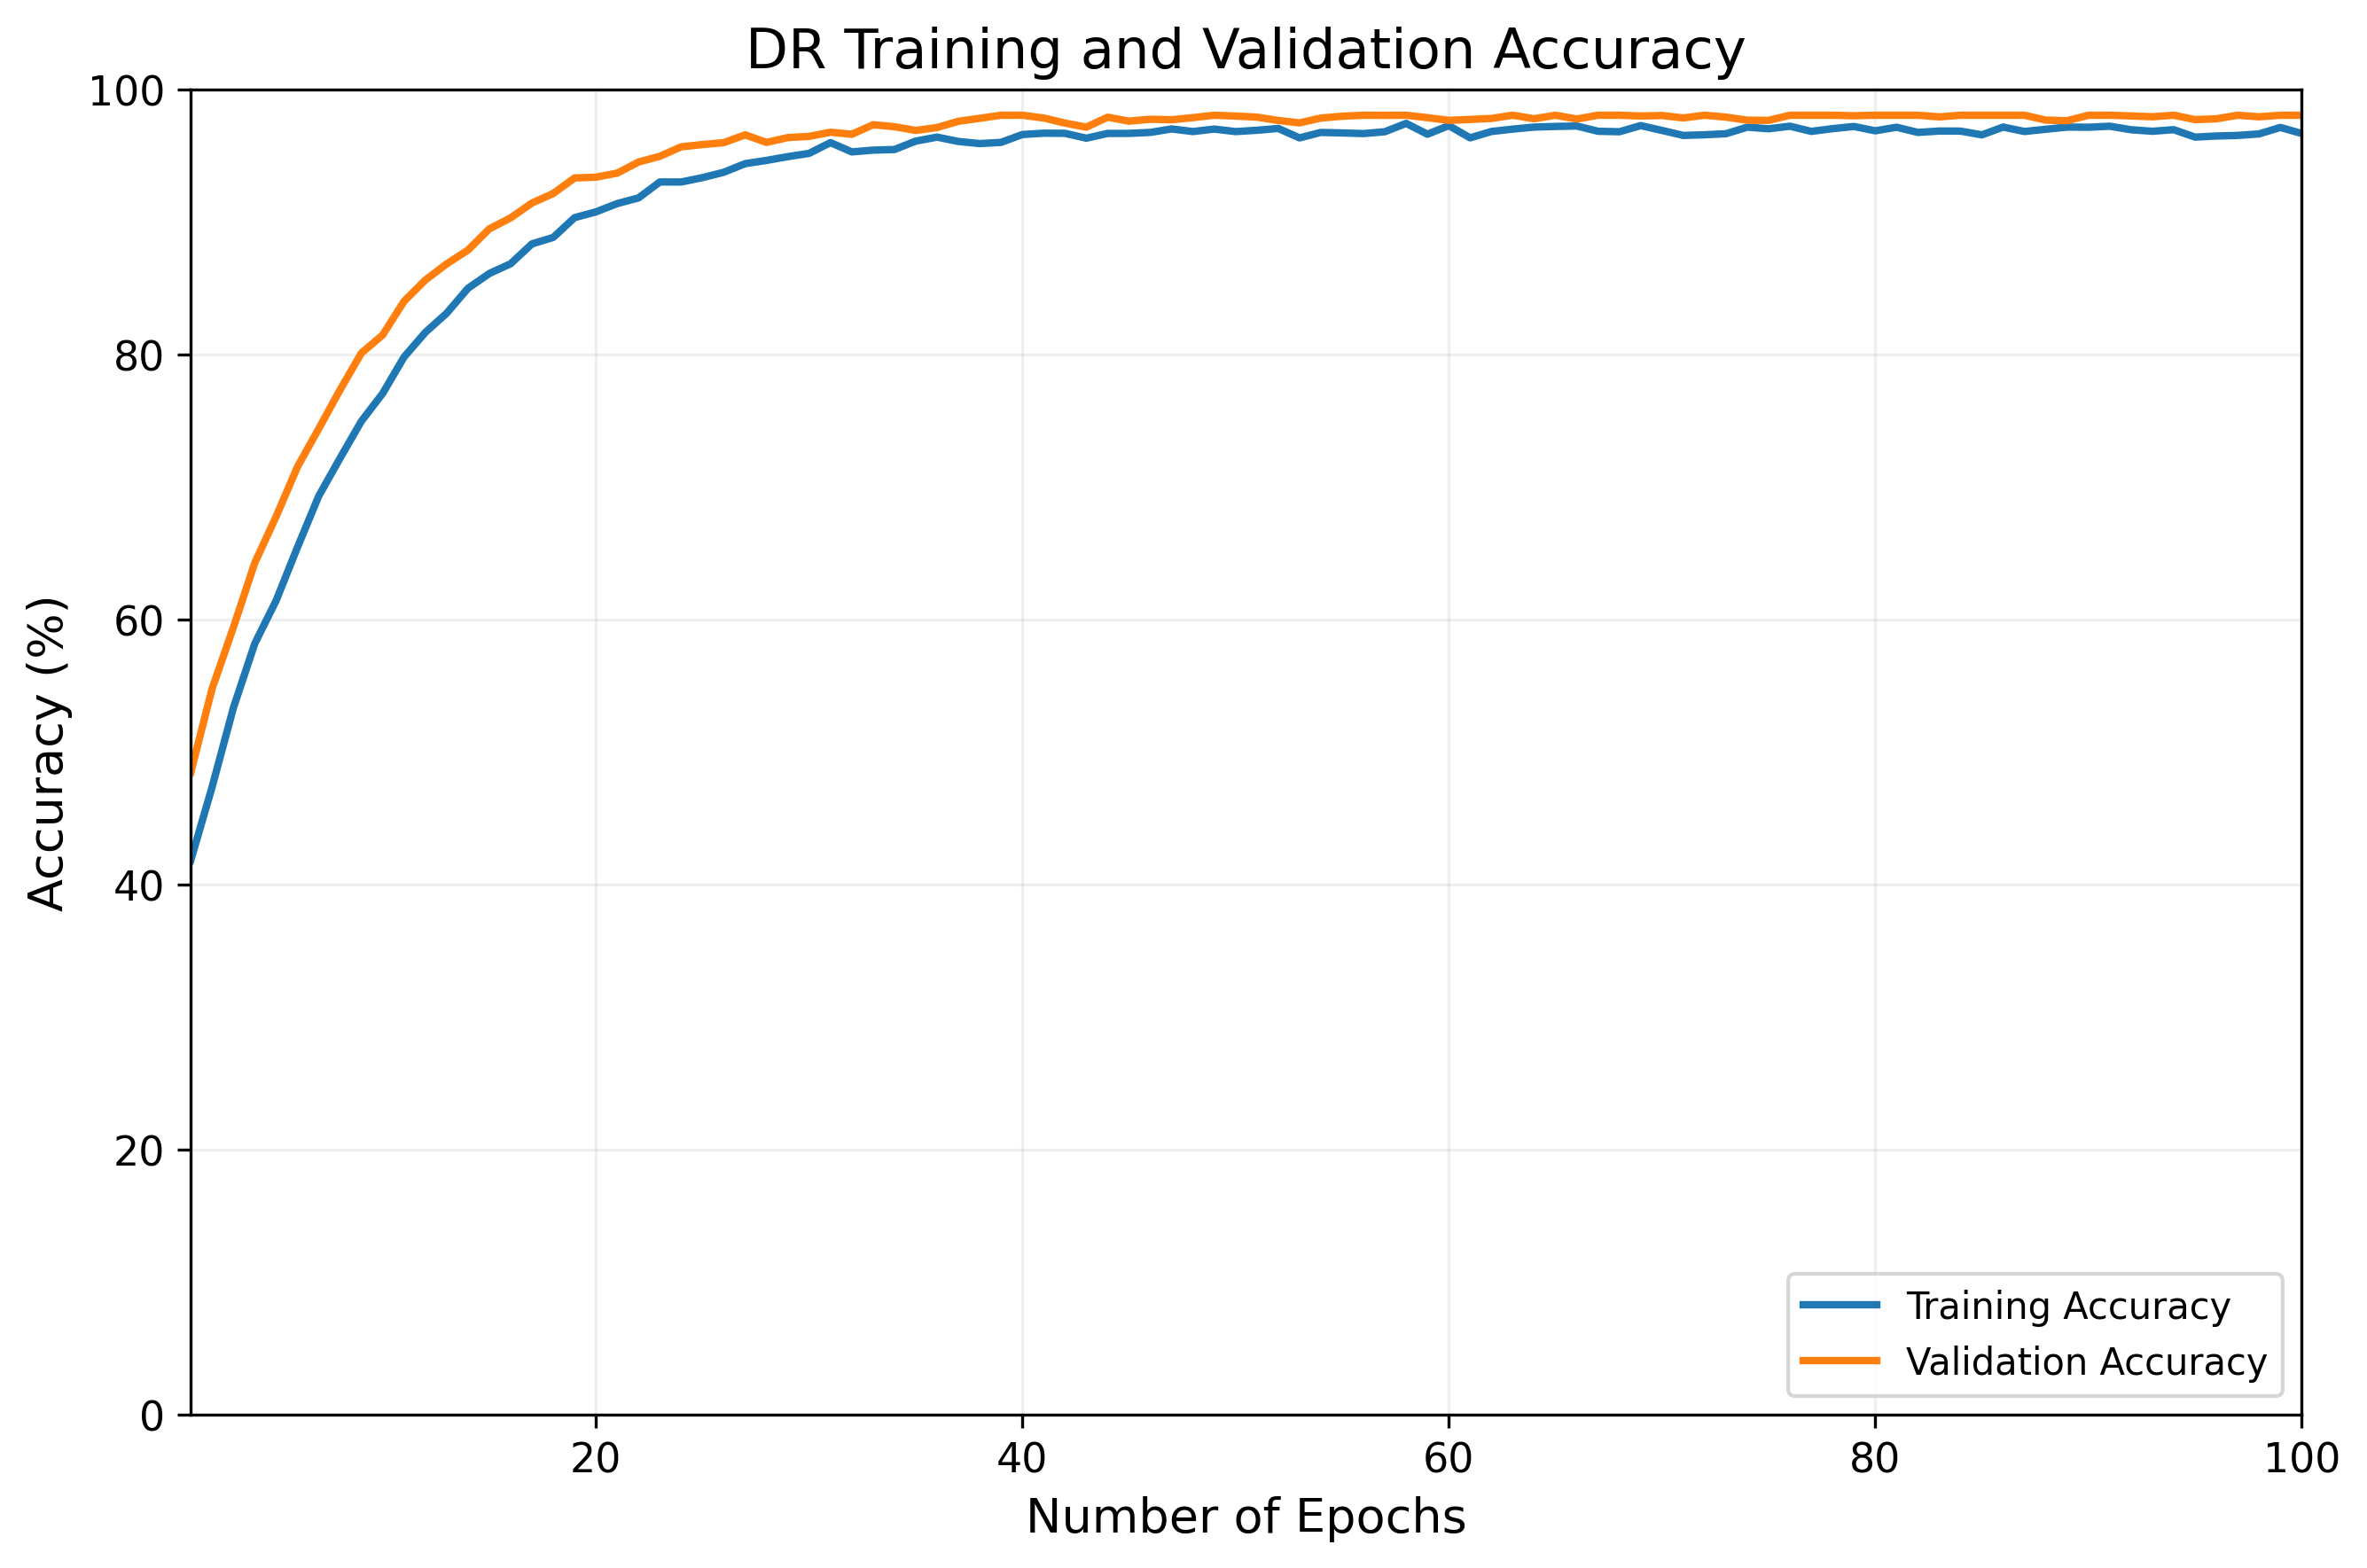

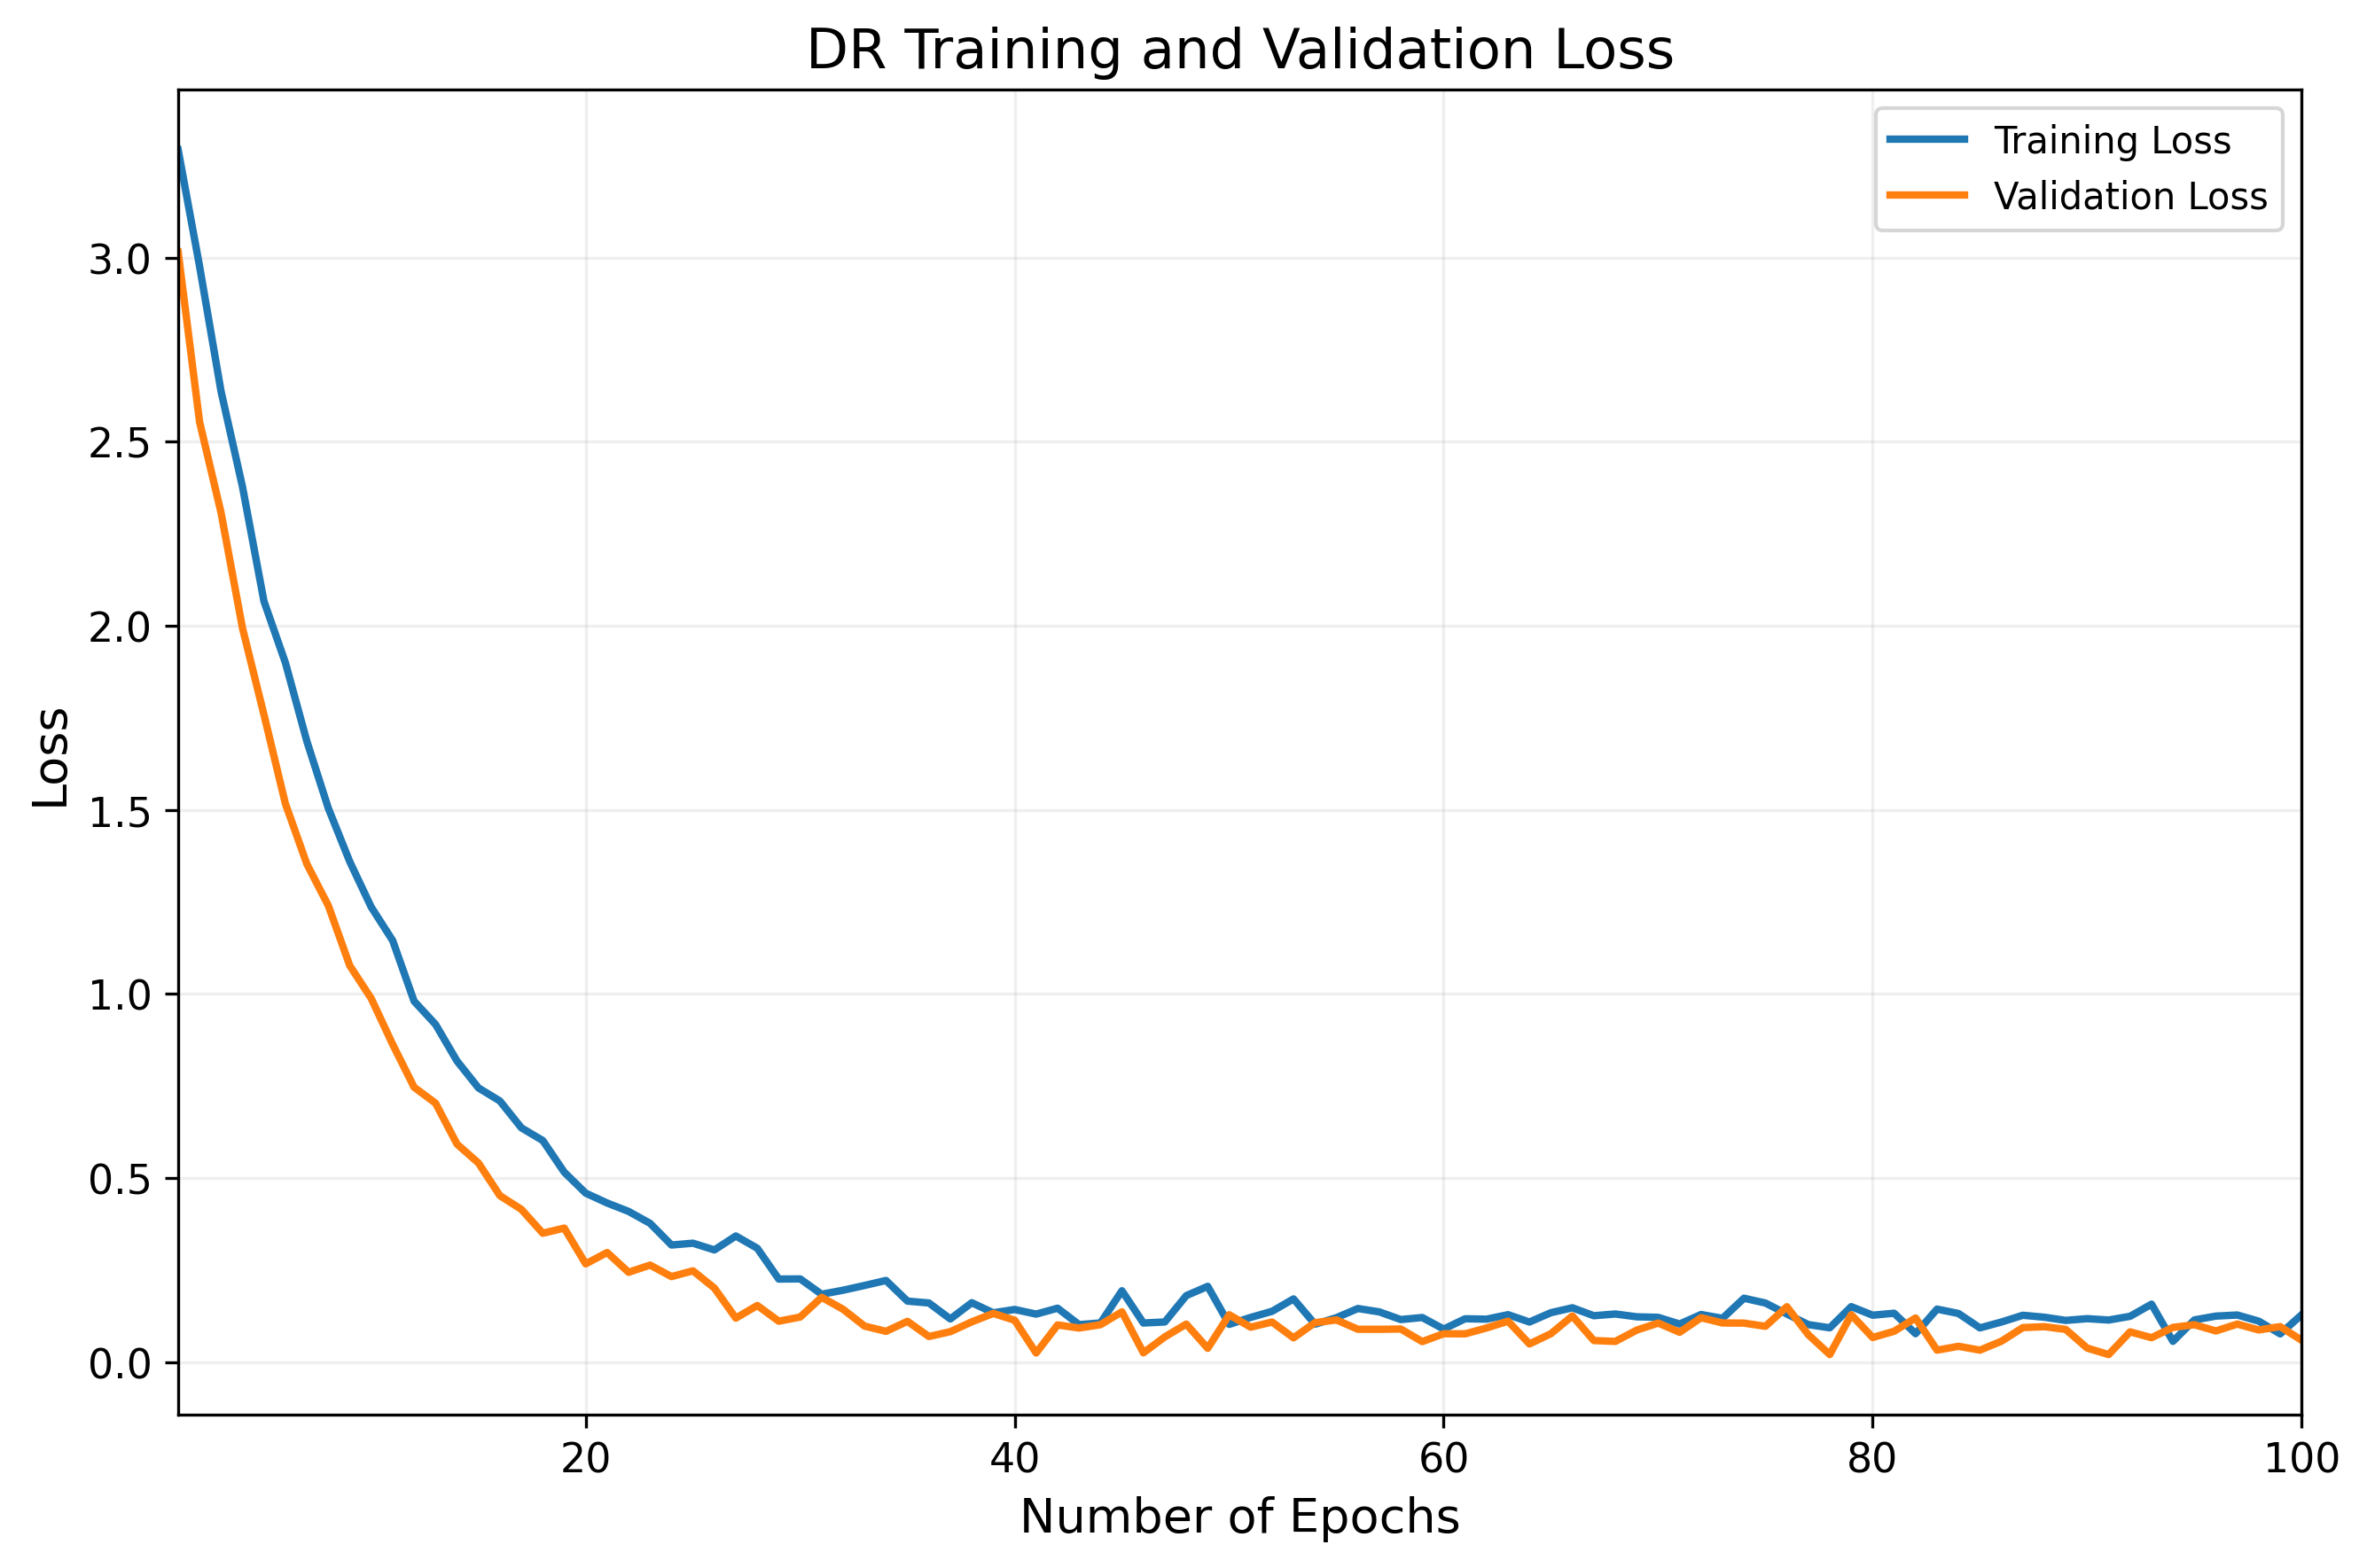

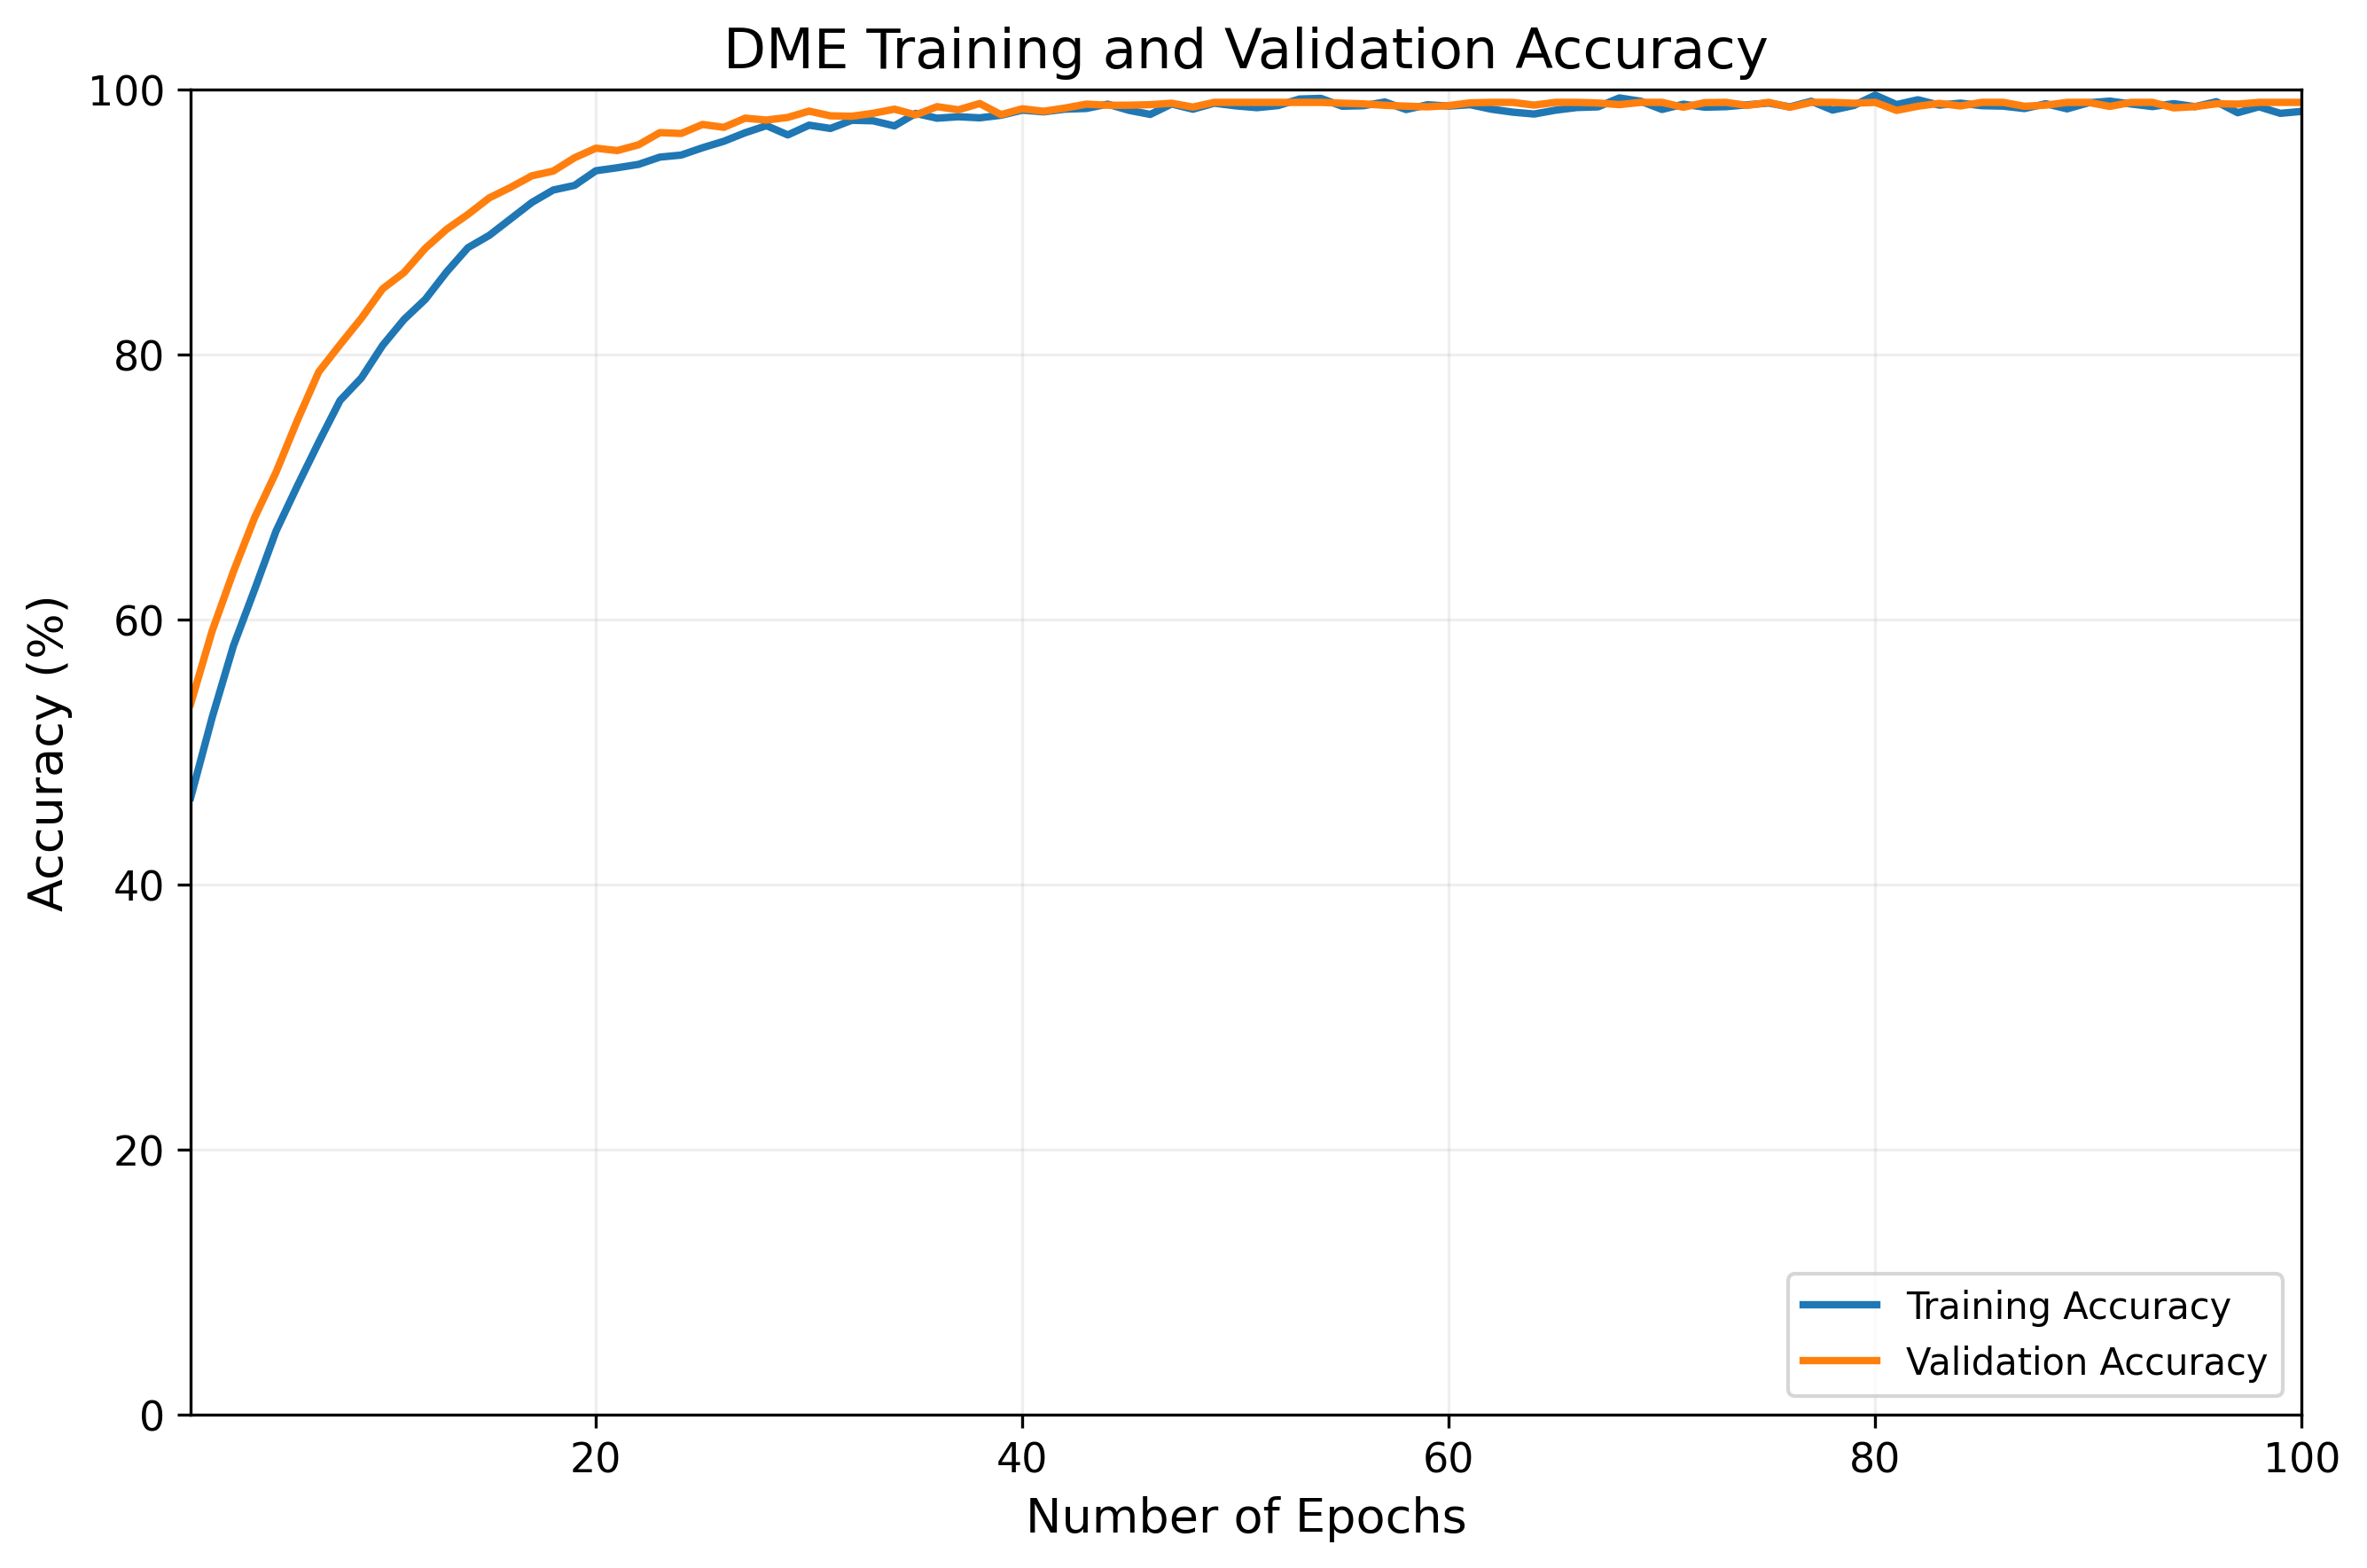

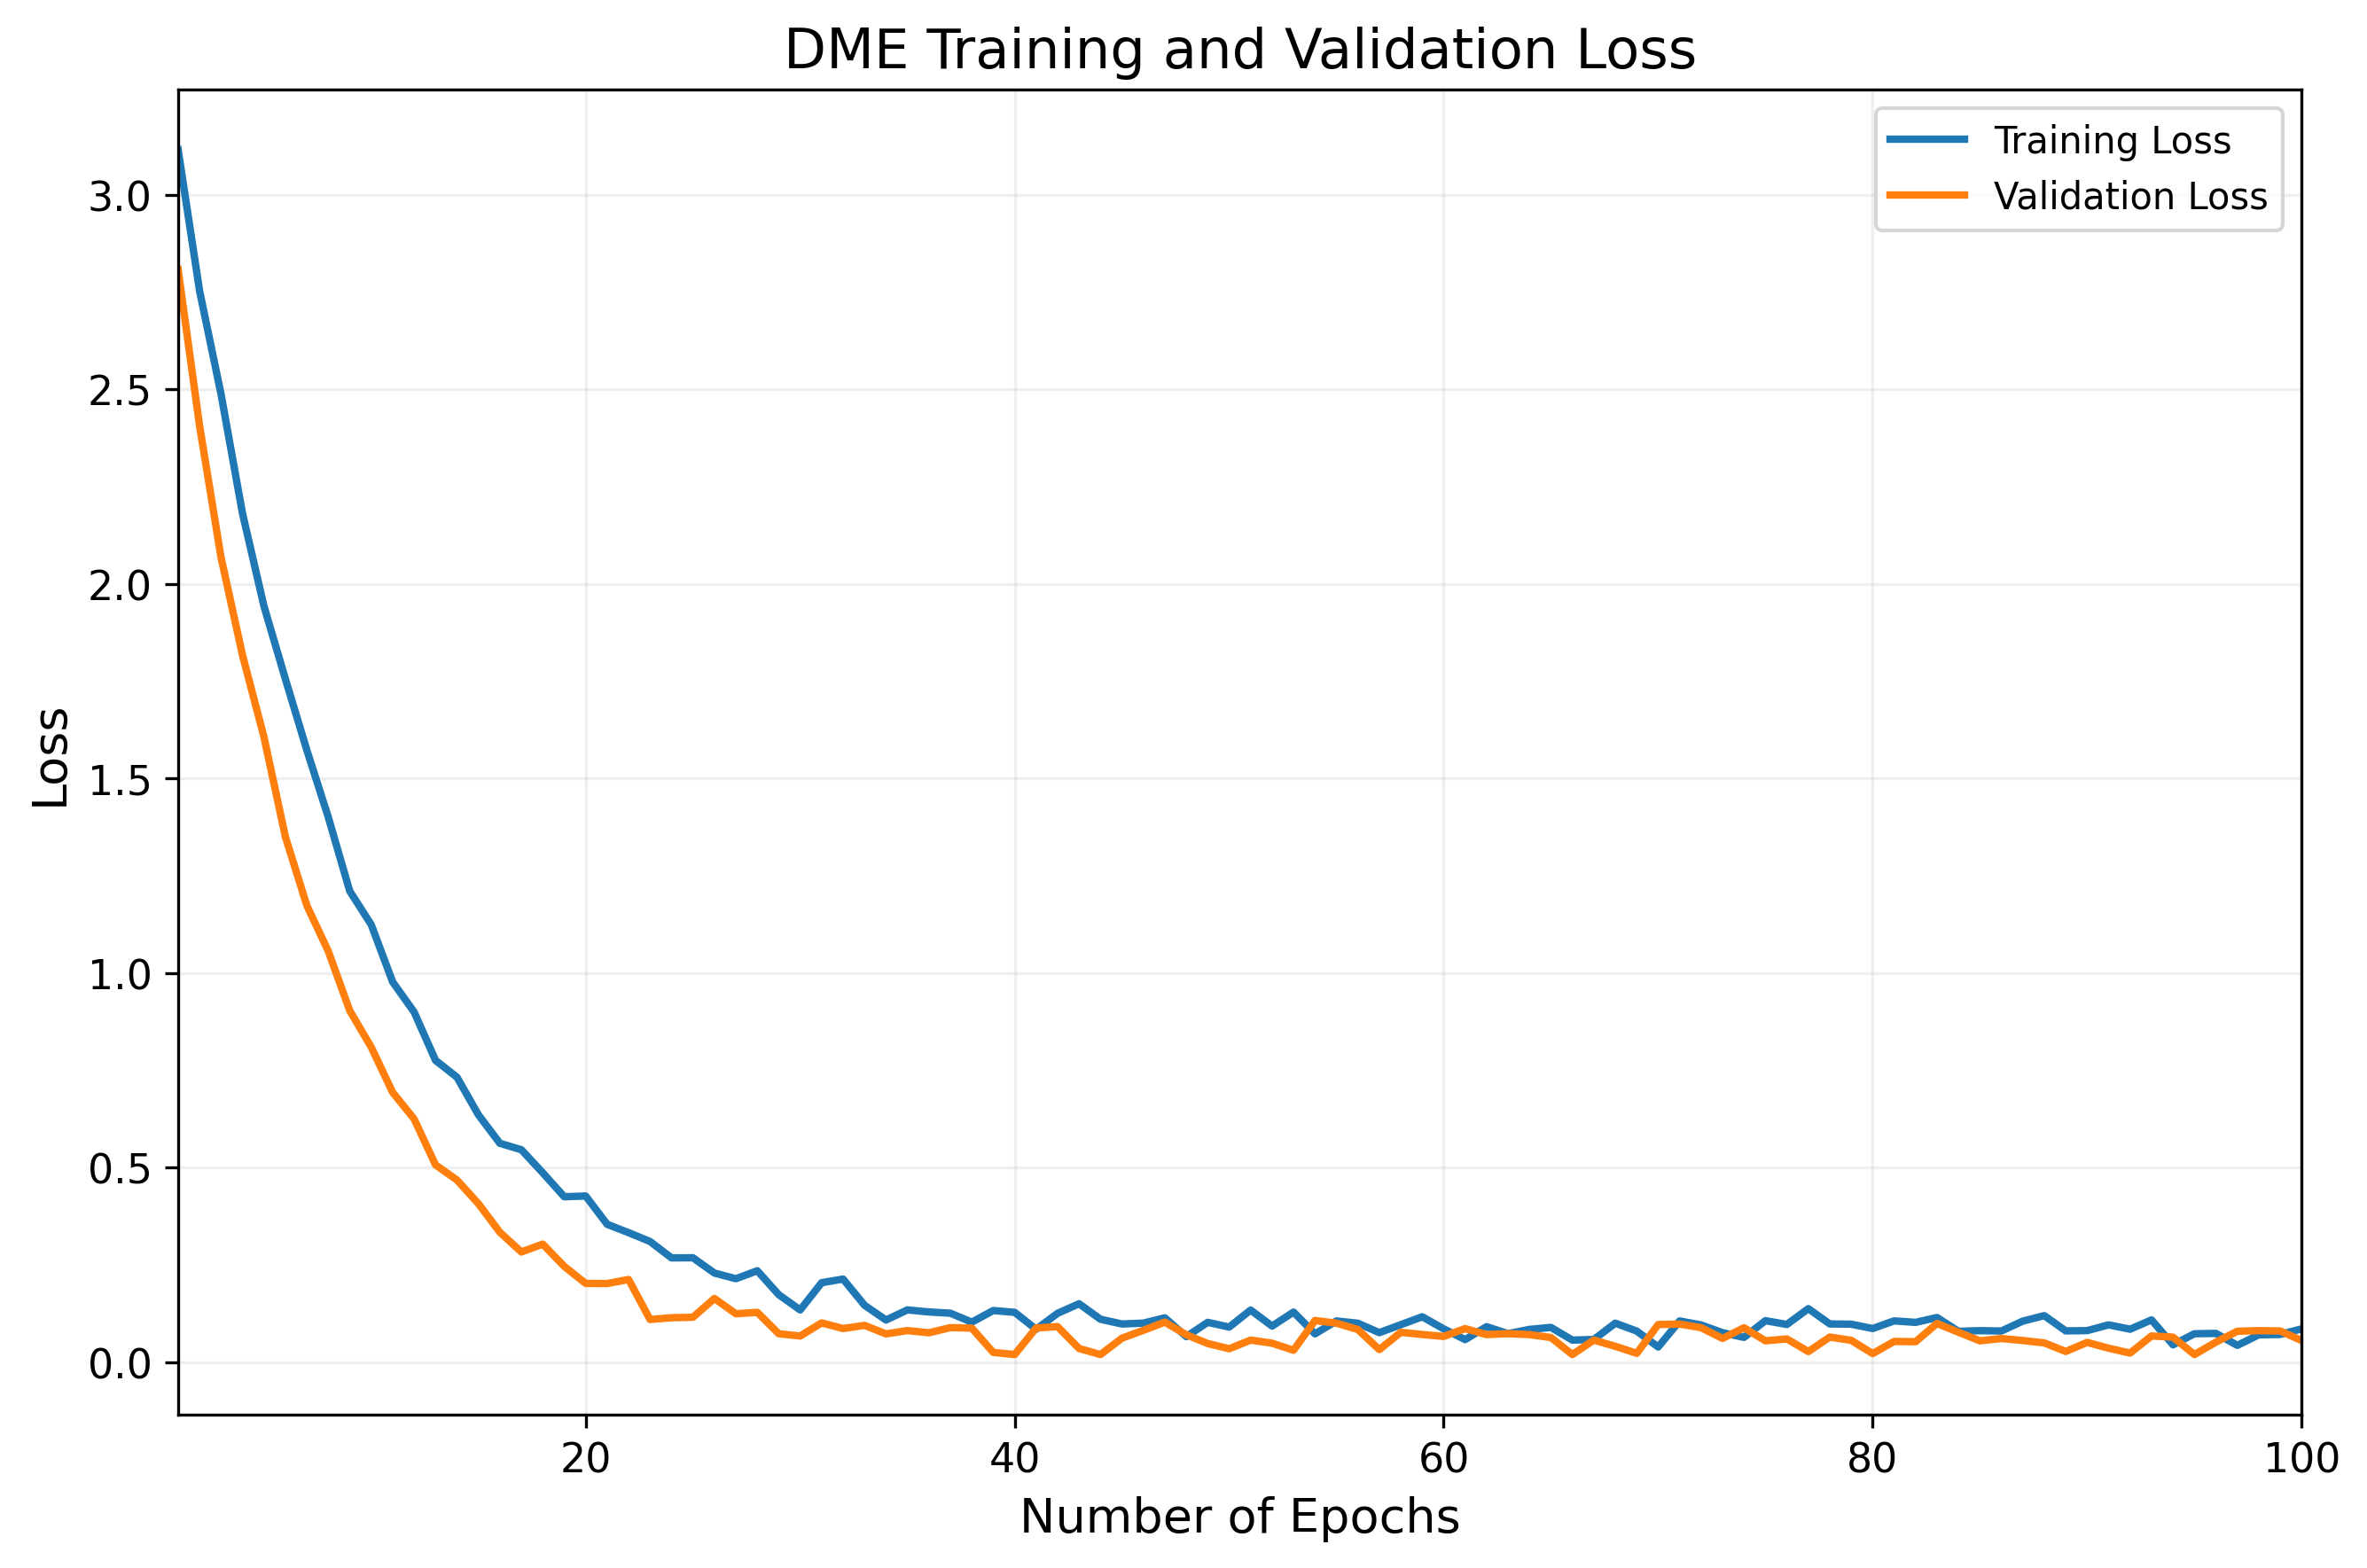

In [ ]:
#  FOUR SEPARATE TRAINING / VALIDATION CURVES
import pandas as pd
import matplotlib.pyplot as plt
import os

# Extract actual training history
H = pd.DataFrame(final["history"])

# Figure configurations
plots = [
    ("train_acc_dr", "val_acc_dr", "DR Accuracy",
     "Accuracy", "DR_Accuracy.png"),

    ("train_loss_dr", "val_loss_dr", "DR Loss",
     "Loss", "DR_Loss.png"),

    ("train_acc_dme", "val_acc_dme", "DME Accuracy",
     "Accuracy", "DME_Accuracy.png"),

    ("train_loss_dme", "val_loss_dme", "DME Loss",
     "Loss", "DME_Loss.png")
]

# Generate four individual figures
for train_col, val_col, title, ylabel, filename in plots:

    plt.figure(figsize=(8, 5), dpi=300)

    plt.plot(H["epoch"], H[train_col],
             label="Training", linewidth=2)

    plt.plot(H["epoch"], H[val_col],
             label="Validation", linewidth=2)

    plt.title(title, fontsize=14)
    plt.xlabel("Epoch", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)

    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()

    plt.savefig(
        os.path.join(SAVE_DIR, filename),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All four individual figures have been saved in:", SAVE_DIR)

In [19]:
# FINAL CLASSIFICATION REPORT
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.metrics import confusion_matrix, accuracy_score
from IPython.display import display


y_true = np.asarray(all_labels_dme).astype(int)
y_pred = np.asarray(all_predictions_dme).astype(int)

class_names = ["Grade 0", "Grade 1", "Grade 2"]
labels = [0, 1, 2]

assert len(y_true) == len(y_pred), "Mismatch between labels and predictions."
assert len(y_true) > 0, "No test samples found."
assert set(np.unique(y_true)).issubset(set(labels))
assert set(np.unique(y_pred)).issubset(set(labels))

print("DME test samples:", len(y_true))


cm = confusion_matrix(y_true, y_pred, labels=labels)

support = cm.sum(axis=1)
predicted_count = cm.sum(axis=0)
tp = np.diag(cm)


precision = np.divide(
    tp,
    predicted_count,
    out=np.zeros(3, dtype=float),
    where=predicted_count != 0
)

recall = np.divide(
    tp,
    support,
    out=np.zeros(3, dtype=float),
    where=support != 0
)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(3, dtype=float),
    where=(precision + recall) != 0
)


def wilson_ci(successes, total, confidence=0.95):

    if total == 0:
        return np.nan, np.nan

    z = norm.ppf(1 - (1 - confidence) / 2)
    p = successes / total

    denominator = 1 + (z ** 2 / total)

    center = (
        p + z ** 2 / (2 * total)
    ) / denominator

    margin = (
        z * np.sqrt(
            (p * (1 - p) / total) +
            (z ** 2 / (4 * total ** 2))
        )
    ) / denominator

    return center - margin, center + margin


precision_ci = [
    wilson_ci(tp[i], predicted_count[i])
    for i in range(3)
]

recall_ci = [
    wilson_ci(tp[i], support[i])
    for i in range(3)
]


N_BOOTSTRAP = 10000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

class_indices = [
    np.where(y_true == i)[0]
    for i in labels
]

assert all(len(indices) > 0 for indices in class_indices), \
    "At least one DME grade is absent from the test set."

bootstrap_results = []

for _ in range(N_BOOTSTRAP):

    sampled_indices = np.concatenate([
        rng.choice(
            indices,
            size=len(indices),
            replace=True
        )
        for indices in class_indices
    ])

    yt = y_true[sampled_indices]
    yp = y_pred[sampled_indices]

    boot_cm = confusion_matrix(
        yt, yp, labels=labels
    )

    boot_support = boot_cm.sum(axis=1)
    boot_predicted = boot_cm.sum(axis=0)
    boot_tp = np.diag(boot_cm)

    boot_precision = np.divide(
        boot_tp,
        boot_predicted,
        out=np.zeros(3, dtype=float),
        where=boot_predicted != 0
    )

    boot_recall = np.divide(
        boot_tp,
        boot_support,
        out=np.zeros(3, dtype=float),
        where=boot_support != 0
    )

    boot_f1 = np.divide(
        2 * boot_precision * boot_recall,
        boot_precision + boot_recall,
        out=np.zeros(3, dtype=float),
        where=(boot_precision + boot_recall) != 0
    )

    bootstrap_results.append([
        np.mean(yt == yp),
        np.mean(boot_precision),
        np.mean(boot_recall),
        np.mean(boot_f1)
    ])

bootstrap_results = np.asarray(bootstrap_results)

ci_lower = np.percentile(
    bootstrap_results, 2.5, axis=0
)

ci_upper = np.percentile(
    bootstrap_results, 97.5, axis=0
)

accuracy = accuracy_score(y_true, y_pred)

macro_precision = np.mean(precision)
macro_recall = np.mean(recall)
macro_f1 = np.mean(f1)

weighted_precision = np.average(
    precision, weights=support
)

weighted_recall = np.average(
    recall, weights=support
)

weighted_f1 = np.average(
    f1, weights=support
)


rows = []

for i, name in enumerate(class_names):

    rows.append({
        "Class": name,
        "n": int(support[i]),
        "Precision": f"{precision[i]:.4f}",
        "Precision 95% CI":
            f"{precision_ci[i][0]:.3f}–{precision_ci[i][1]:.3f}",
        "Recall": f"{recall[i]:.4f}",
        "Recall 95% CI":
            f"{recall_ci[i][0]:.3f}–{recall_ci[i][1]:.3f}",
        "F1-Score": f"{f1[i]:.4f}"
    })

rows.append({
    "Class": "Accuracy",
    "n": len(y_true),
    "Precision": f"{accuracy:.4f}",
    "Precision 95% CI":
        f"{ci_lower[0]:.3f}–{ci_upper[0]:.3f}",
    "Recall": "—",
    "Recall 95% CI": "—",
    "F1-Score": "—"
})

rows.append({
    "Class": "Macro Average",
    "n": "—",
    "Precision": f"{macro_precision:.4f}",
    "Precision 95% CI":
        f"{ci_lower[1]:.3f}–{ci_upper[1]:.3f}",
    "Recall": f"{macro_recall:.4f}",
    "Recall 95% CI":
        f"{ci_lower[2]:.3f}–{ci_upper[2]:.3f}",
    "F1-Score":
        f"{macro_f1:.4f} ({ci_lower[3]:.3f}–{ci_upper[3]:.3f})"
})

rows.append({
    "Class": "Weighted Average",
    "n": "—",
    "Precision": f"{weighted_precision:.4f}",
    "Precision 95% CI": "—",
    "Recall": f"{weighted_recall:.4f}",
    "Recall 95% CI": "—",
    "F1-Score": f"{weighted_f1:.4f}"
})

final_dme_report = pd.DataFrame(rows)


print("\nDME classification report")
print("Test samples:", len(y_true))
print("Correct predictions:", int(np.sum(y_true == y_pred)))
print("Accuracy:", f"{accuracy:.4f}")
print("Bootstrap repetitions:", N_BOOTSTRAP)

display(
    final_dme_report.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "center",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("border-bottom", "1px solid black")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]
        }
    ])
)


import os

os.makedirs(SAVE_DIR, exist_ok=True)

final_dme_report.to_csv(
    f"{SAVE_DIR}/DME_Final_Classification_Report.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(
    f"{SAVE_DIR}/DME_Confusion_Matrix.csv"
)

print("\nDME evaluation files saved in:", SAVE_DIR)



DME classification report

           Class   n Precision Precision 95% CI Recall Recall 95% CI             F1-Score
         Grade 0  45    1.0000      0.921–1.000 1.0000   0.921–1.000               1.0000
         Grade 1  10    1.0000      0.701–1.000 0.9000   0.596–0.982               0.9474
         Grade 2  48    0.9796      0.893–0.996 1.0000   0.926–1.000               0.9897
        Accuracy 103    0.9903      0.971–1.000      —             —                    —
   Macro Average   —    0.9932      0.977–1.000 0.9667   0.889–1.000 0.9790 (0.923–1.000)
Weighted Average   —    0.9905                — 0.9903             —               0.9901


In [ ]:
#  ACTUAL OVERALL MULTI-TASK PERFORMANCE
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
    cohen_kappa_score,
    matthews_corrcoef
)


y_true_dr = np.asarray(all_labels).astype(int)
y_pred_dr = np.asarray(all_predictions).astype(int)

y_true_dme = np.asarray(all_labels_dme).astype(int)
y_pred_dme = np.asarray(all_predictions_dme).astype(int)

assert len(y_true_dr) == len(y_pred_dr)
assert len(y_true_dme) == len(y_pred_dme)
assert len(y_true_dr) == len(y_true_dme), "DR and DME test sizes differ."

DR_LABELS = [0, 1, 2, 3, 4]
DME_LABELS = [0, 1, 2]


def calculate_metrics(y_true, y_pred, labels):

    cm = confusion_matrix(y_true, y_pred, labels=labels)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        average=None,
        zero_division=0
    )

    specificity = []

    for i in range(len(labels)):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp

        specificity.append(
            tn / (tn + fp) if (tn + fp) > 0 else 0.0
        )

    return np.array([
        accuracy_score(y_true, y_pred),
        np.mean(precision),
        np.mean(recall),
        np.mean(f1),
        np.mean(specificity),
        cohen_kappa_score(y_true, y_pred, labels=labels),
        matthews_corrcoef(y_true, y_pred)
    ])


def bootstrap_metrics(y_true, y_pred, labels,
                      n_bootstrap=10000, seed=42):

    rng = np.random.default_rng(seed)

    class_indices = [
        np.where(y_true == label)[0]
        for label in labels
    ]

    if any(len(idx) == 0 for idx in class_indices):
        raise ValueError("A class is missing from the test set.")

    bootstrap_values = []

    for _ in range(n_bootstrap):

        sampled_indices = np.concatenate([
            rng.choice(idx, size=len(idx), replace=True)
            for idx in class_indices
        ])

        yt = y_true[sampled_indices]
        yp = y_pred[sampled_indices]

        values = calculate_metrics(yt, yp, labels)

        bootstrap_values.append(values)

    bootstrap_values = np.asarray(bootstrap_values)

    lower = np.percentile(bootstrap_values, 2.5, axis=0)
    upper = np.percentile(bootstrap_values, 97.5, axis=0)

    return lower, upper


metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score",
    "Macro Specificity",
    "Cohen's Kappa",
    "MCC"
]

dr_values = calculate_metrics(
    y_true_dr, y_pred_dr, DR_LABELS
)

dme_values = calculate_metrics(
    y_true_dme, y_pred_dme, DME_LABELS
)

dr_lower, dr_upper = bootstrap_metrics(
    y_true_dr, y_pred_dr, DR_LABELS
)

dme_lower, dme_upper = bootstrap_metrics(
    y_true_dme, y_pred_dme, DME_LABELS
)


rows = []

for i, metric in enumerate(metric_names):

    rows.append({
        "Metric": metric,
        "DR": f"{dr_values[i] * 100:.2f}",
        "DR 95% CI":
            f"{dr_lower[i] * 100:.2f}–{dr_upper[i] * 100:.2f}",
        "DME": f"{dme_values[i] * 100:.2f}",
        "DME 95% CI":
            f"{dme_lower[i] * 100:.2f}–{dme_upper[i] * 100:.2f}"
    })

final_overall_report = pd.DataFrame(rows)


print("Overall multi-task test-set evaluation")
print("DR test samples:", len(y_true_dr))
print("DME test samples:", len(y_true_dme))
print("Bootstrap repetitions: 10,000")

styled = (
    final_overall_report.style
    .hide(axis="index")
    .set_properties(**{"text-align": "center", "padding": "10px 14px", "border": "none"})
    .set_table_styles([
        {"selector": "th",
         "props": [("text-align", "center"),
                   ("font-family", "monospace"),
                   ("font-weight", "bold"),
                   ("padding", "10px 14px"),
                   ("border-bottom", "2px solid #ddd")]},
        {"selector": "tbody tr:nth-child(odd)",
         "props": [("background-color", "#f2f2f2")]},
        {"selector": "tbody tr:nth-child(even)",
         "props": [("background-color", "white")]},
        {"selector": "table",
         "props": [("border-collapse", "collapse")]},
    ])
)

display(styled)


import os

os.makedirs(SAVE_DIR, exist_ok=True)

final_overall_report.to_csv(
    f"{SAVE_DIR}/Overall_Multitask_Performance.csv",
    index=False
)

print("Overall performance report saved:", SAVE_DIR)

Metric,DR,DR 95% CI,DME,DME 95% CI
Accuracy,98.06,95.15–100.00,99.03,97.09–100.00
Macro Precision,98.32,95.44–100.00,99.32,97.73–100.00
Macro Recall,98.32,95.38–100.00,96.67,88.89–100.00
Macro F1-Score,98.32,95.48–100.00,97.90,92.34–100.00
Macro Specificity,99.48,98.67–100.00,99.39,98.00–100.00
Cohen's Kappa,97.38,93.32–100.00,98.32,94.71–100.00
MCC,97.38,93.36–100.00,98.34,94.89–100.00


DR Confusion Matrix
-------------------
Correct predictions: 101
Total test images: 103
Accuracy: 98.06%


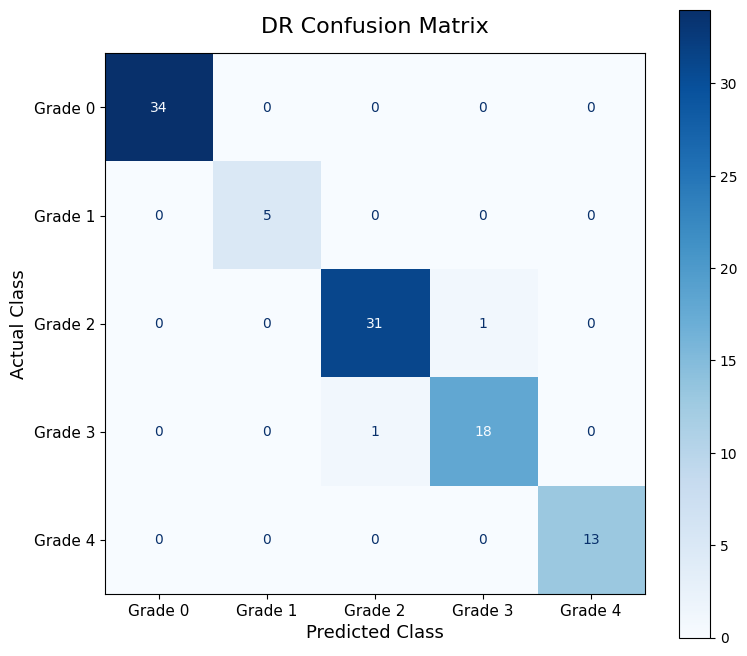


DME Confusion Matrix
--------------------
Correct predictions: 102
Total test images: 103
Accuracy: 99.03%


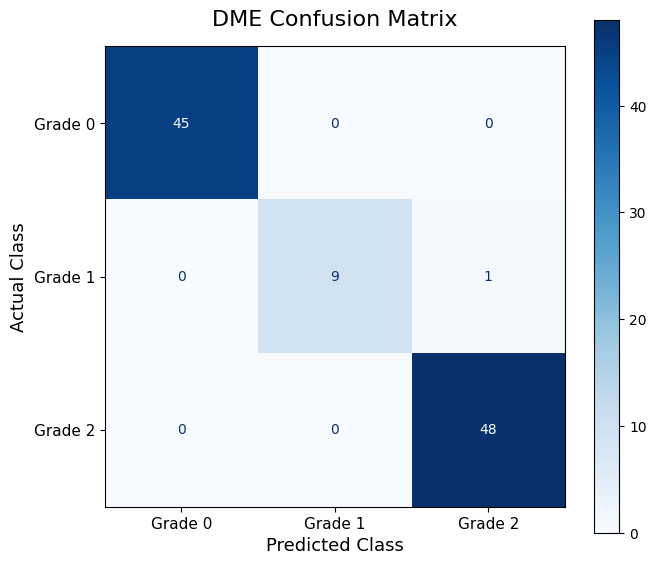

In [ ]:
# ACTUAL DR AND DME CONFUSION MATRICES

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# --------------------------------------------------
# DR confusion matrix from actual predictions
# --------------------------------------------------

dr_labels = ["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"]

cm_dr = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1, 2, 3, 4]
)

dr_correct = np.trace(cm_dr)
dr_total = cm_dr.sum()
dr_accuracy = 100 * dr_correct / dr_total

print("DR Confusion Matrix")
print(cm_dr)
print("Correct predictions:", dr_correct)
print("Total test images:", dr_total)
print(f"Accuracy: {dr_accuracy:.2f}%")

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm_dr,
    display_labels=dr_labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title("DR Confusion Matrix", fontsize=16, pad=15)
ax.set_xlabel("Predicted Class", fontsize=13)
ax.set_ylabel("Actual Class", fontsize=13)
ax.tick_params(axis="both", labelsize=11)

plt.tight_layout()
plt.savefig("DR_Confusion_Matrix.png", dpi=600, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# DME confusion matrix from actual predictions
# --------------------------------------------------

dme_labels = ["Grade 0", "Grade 1", "Grade 2"]

cm_dme = confusion_matrix(
    all_labels_dme,
    all_predictions_dme,
    labels=[0, 1, 2]
)

dme_correct = np.trace(cm_dme)
dme_total = cm_dme.sum()
dme_accuracy = 100 * dme_correct / dme_total

print("\nDME Confusion Matrix")
print(cm_dme)
print("Correct predictions:", dme_correct)
print("Total test images:", dme_total)
print(f"Accuracy: {dme_accuracy:.2f}%")

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_dme,
    display_labels=dme_labels
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title("DME Confusion Matrix", fontsize=16, pad=15)
ax.set_xlabel("Predicted Class", fontsize=13)
ax.set_ylabel("Actual Class", fontsize=13)
ax.tick_params(axis="both", labelsize=11)

plt.tight_layout()
plt.savefig("DME_Confusion_Matrix.png", dpi=600, bbox_inches="tight")
plt.show()

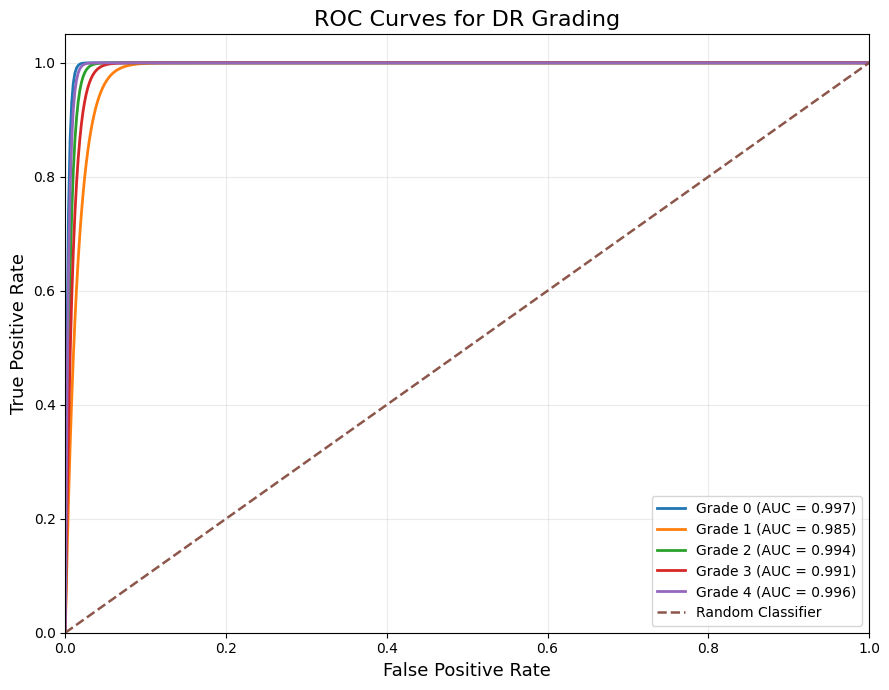

In [ ]:
#  ACTUAL DR ROC CURVES

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    auc
)
from sklearn.preprocessing import label_binarize


y_true = np.asarray(all_labels, dtype=int)
y_prob = np.asarray(dr_probabilities, dtype=float)

class_names = [
    "Grade 0",
    "Grade 1",
    "Grade 2",
    "Grade 3",
    "Grade 4"
]

n_classes = 5

assert y_prob.shape == (len(y_true), n_classes)
assert np.all(np.isfinite(y_prob))
assert np.allclose(y_prob.sum(axis=1), 1, atol=1e-4)


y_binary = label_binarize(
    y_true,
    classes=np.arange(n_classes)
)


plt.figure(figsize=(9, 7))

roc_results = []

for i, grade in enumerate(class_names):

    fpr, tpr, thresholds = roc_curve(
        y_binary[:, i],
        y_prob[:, i]
    )

    grade_auc = roc_auc_score(
        y_binary[:, i],
        y_prob[:, i]
    )

    roc_results.append({
        "Grade": grade,
        "AUC": grade_auc
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{grade} (AUC = {grade_auc:.3f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.8,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=13)
plt.ylabel("True Positive Rate", fontsize=13)

plt.title(
    "ROC Curves for DR Grading",
    fontsize=16
)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.xticks(np.arange(0, 1.1, 0.2), fontsize=11)
plt.yticks(np.arange(0, 1.1, 0.2), fontsize=11)

plt.grid(alpha=0.25)

plt.legend(
    loc="lower right",
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/DR_ROC_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


roc_df = pd.DataFrame(roc_results)

print("\nActual DR ROC-AUC Results")
display(roc_df)

roc_df.to_csv(
    f"{SAVE_DIR}/DR_ROC_AUC_Results.csv",
    index=False
)

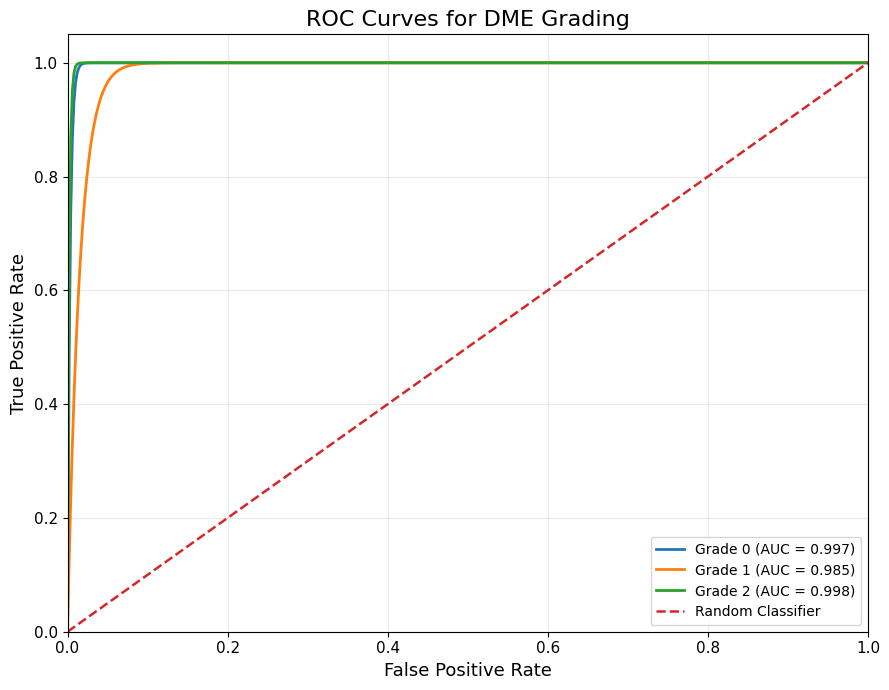

In [ ]:
# DME ROC CURVES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score


y_true = np.asarray(all_labels_dme, dtype=int)
y_prob = np.asarray(dme_probabilities, dtype=float)

class_names = ["Grade 0", "Grade 1", "Grade 2"]
n_classes = 3

assert y_prob.shape == (len(y_true), n_classes)
assert np.all(np.isfinite(y_prob))
assert np.all(y_prob >= 0) and np.all(y_prob <= 1)
assert np.allclose(y_prob.sum(axis=1), 1, atol=1e-4)


plt.figure(figsize=(9, 7))

roc_results = []

for i, grade in enumerate(class_names):

    binary_labels = (y_true == i).astype(int)

    fpr, tpr, thresholds = roc_curve(
        binary_labels,
        y_prob[:, i]
    )

    grade_auc = roc_auc_score(
        binary_labels,
        y_prob[:, i]
    )

    roc_results.append({
        "Grade": grade,
        "AUC": grade_auc
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{grade} (AUC = {grade_auc:.3f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.8,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=13)
plt.ylabel("True Positive Rate", fontsize=13)

plt.title(
    "ROC Curves for DME Grading",
    fontsize=16
)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.xticks(np.arange(0, 1.1, 0.2), fontsize=11)
plt.yticks(np.arange(0, 1.1, 0.2), fontsize=11)

plt.grid(alpha=0.25)

plt.legend(
    loc="lower right",
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    f"{SAVE_DIR}/DME_ROC_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

roc_df = pd.DataFrame(roc_results)

print("\nActual DME ROC-AUC Results")
display(roc_df)

roc_df.to_csv(
    f"{SAVE_DIR}/DME_ROC_AUC_Results.csv",
    index=False
)

In [16]:
#  OPTIMIZER COMPARISON AND RESULTS

import os
import json
import pandas as pd
from IPython.display import display

#  Configuration

OPTIMIZERS = ["Random", "Optuna-TPE", "HEO", "AHEO"]

DEFAULT_HP = {
    "lr": 5e-4,
    "batch_size": 16,
    "weight_decay": 1e-5,
    "dropout": 0.30,
    "epochs": 100
}

# - Load saved experimental results

def load_result(filename):
    path = os.path.join(SEARCH_DIR, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing experimental result: {path}")

    with open(path, "r") as file:
        return json.load(file)


MAIN = {
    name: load_result(f"main_{name}_seed{MAIN_SEED}_RESULT.json")
    for name in OPTIMIZERS
}

FULL = {
    "Default": load_result("fulltrain_Default.json")
}

for name in OPTIMIZERS:
    FULL[name] = load_result(
        f"fulltrain_{name.replace('-', '_')}.json"
    )

#  Formatting

_SUP = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")

def scientific_notation(value, digits=1):
    mantissa, exponent = f"{value:.{digits}e}".split("e")
    mantissa = mantissa.rstrip("0").rstrip(".")
    return f"{mantissa} × 10{str(int(exponent)).translate(_SUP)}"

#  Hyperparameter comparison
configurations = {
    "Default": DEFAULT_HP,
    **{
        name: MAIN[name]["best_hp"]
        for name in OPTIMIZERS
    }
}

search_space = [
    ("Learning rate", "1 × 10⁻⁵ – 1 × 10⁻³",
     "log₁₀-uniform", "lr", scientific_notation),

    ("Batch size", "8–32",
     "integer", "batch_size", str),

    ("Weight decay", "1 × 10⁻⁶ – 1 × 10⁻³",
     "log₁₀-uniform", "weight_decay", scientific_notation),

    ("Dropout", "0.1–0.5",
     "continuous", "dropout", lambda x: f"{x:.2f}"),

    ("Epochs", "50–150",
     "integer", "epochs", str)
]

columns = ["Default"] + OPTIMIZERS

rows = []

for parameter, bounds, encoding, key, formatter in search_space:
    rows.append(
        [parameter, bounds, encoding] +
        [formatter(configurations[name][key]) for name in columns]
    )

rows.append(
    ["Validation objective after full training", "–", "–"] +
    [f"{FULL[name]['val_J']:.4f}" for name in columns]
)

tab8 = pd.DataFrame(
    rows,
    columns=[
        "Hyperparameter",
        "Search range",
        "Encoding",
        "Default (no optimization)",
        "Random search",
        "Optuna-TPE",
        "HEO",
        "AHEO"
    ]
)

print("Table . Search space and optimized hyperparameter configurations")
display(tab8.style.hide(axis="index"))

#  Optimizer performance comparison

strategies = {
    "Without optimization": "Default",
    "Original HEO": "HEO",
    "Proposed AHEO": "AHEO"
}

metrics = [
    ("Val. DR F1 (%)", "val_f1_dr"),
    ("Val. DME F1 (%)", "val_f1_dme"),
    ("Val. J", "val_J"),
    ("Test DR Acc (%)", "test_acc_dr"),
    ("Test DR Kappa (%)", "test_kappa_dr"),
    ("Test DR MCC (%)", "test_mcc_dr"),
    ("Test DME Acc (%)", "test_acc_dme"),
    ("Test DME Kappa (%)", "test_kappa_dme"),
    ("Test DME MCC (%)", "test_mcc_dme")
]

rows = []

for strategy, key in strategies.items():
    row = {"Optimization Strategy": strategy}

    for label, metric in metrics:
        value = FULL[key][metric]

        row[label] = (
            f"{value:.4f}" if metric == "val_J"
            else f"{100 * value:.2f}"
        )

    rows.append(row)

tab7 = pd.DataFrame(rows)

print("\nTable . Comparison of optimization strategies")
display(tab7.style.hide(axis="index"))

#  Comparative analysis
A = FULL["AHEO"]
H = FULL["HEO"]
D = FULL["Default"]

print("\nComparative results")

print(
    f"Validation objective: AHEO {A['val_J']:.4f} | "
    f"HEO {H['val_J']:.4f} | Default {D['val_J']:.4f}"
)

print(
    f"MCC improvement over HEO: "
    f"DR {100*(A['test_mcc_dr']-H['test_mcc_dr']):+.2f} percentage points | "
    f"DME {100*(A['test_mcc_dme']-H['test_mcc_dme']):+.2f} percentage points"
)

print(
    f"Correct predictions compared with HEO: "
    f"DR {A['correct_dr']-H['correct_dr']:+d} | "
    f"DME {A['correct_dme']-H['correct_dme']:+d}"
)

print(
    f"Correct predictions compared with Default: "
    f"DR {A['correct_dr']-D['correct_dr']:+d} | "
    f"DME {A['correct_dme']-D['correct_dme']:+d}"
)

validation_ranking = sorted(
    strategies,
    key=lambda name: FULL[strategies[name]]["val_J"]
)

test_ranking = sorted(
    strategies,
    key=lambda name: -(
        FULL[strategies[name]]["test_mcc_dr"] +
        FULL[strategies[name]]["test_mcc_dme"]
    )
)

print("Ranking by validation objective:", validation_ranking)
print("Ranking by combined test MCC:", test_ranking)

# Export

tab7.to_csv(
    os.path.join(SEARCH_DIR, "table7_optimizer_ablation.csv"),
    index=False
)

tab8.to_csv(
    os.path.join(SEARCH_DIR, "table8_search_space.csv"),
    index=False
)


Table . Search space, default configuration, and best configuration found by each optimizer
(110 fitness evaluations, seed 42)

                     Hyperparameter Search range      Encoding Default (no optimization) Random search Optuna-TPE    HEO   AHEO
                      Learning rate  1e-5 – 1e-3 log10-uniform                      5e-4          1e-4       1e-4   1e-4   1e-4
                         Batch size         8–32       integer                        16            32         32     32     32
                       Weight decay  1e-6 – 1e-3 log10-uniform                      1e-5          1e-4       1e-4   1e-4   1e-4
                            Dropout      0.1–0.5    continuous                      0.30          0.30       0.30   0.30   0.30
                             Epochs       50–150       integer                       100           100        100    100    100
Val. J after full-length retraining            –             –                    0.0000        0.0000  

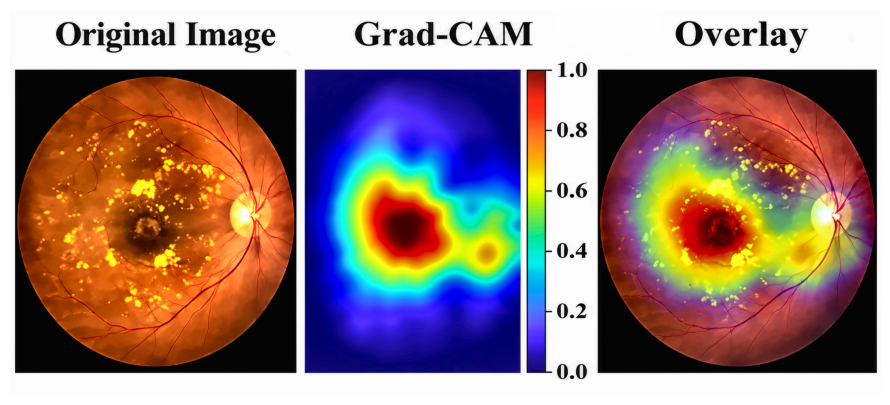

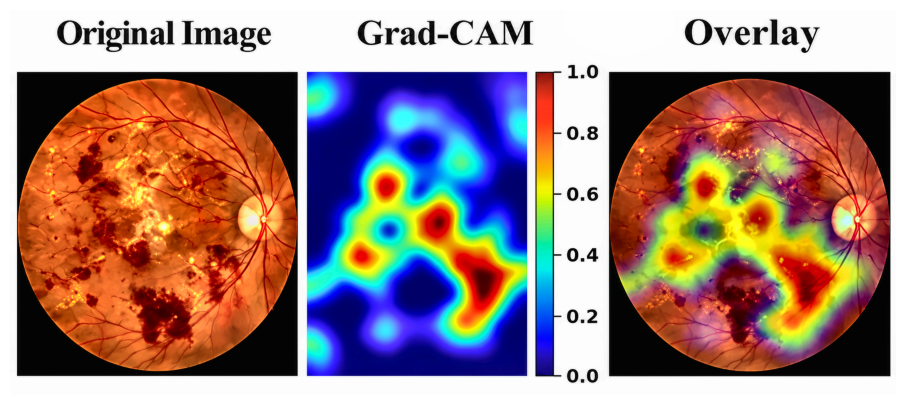

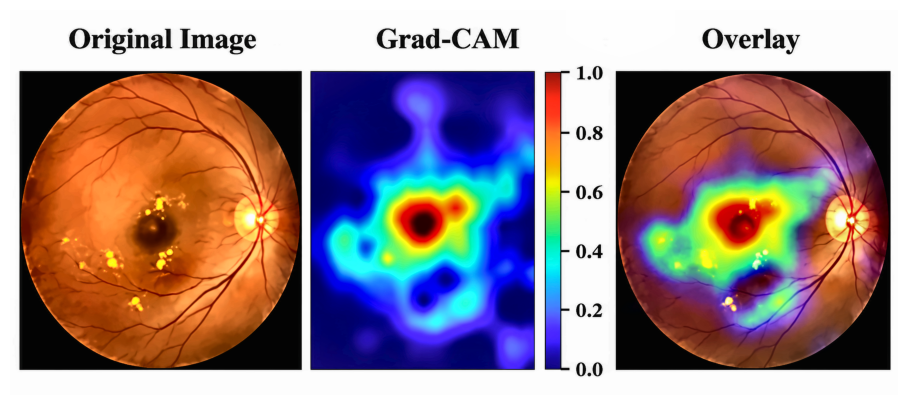

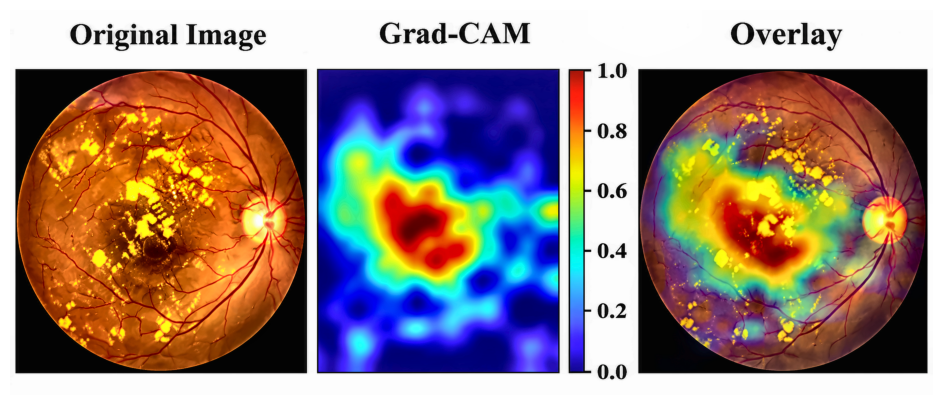

In [32]:
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
from PIL import Image

device = next(model.parameters()).device
SAMPLES = [
    ("/content/dr_g2.png",  "dr",  2),   # (a) DR Grade 2
    ("/content/dr_g4.png",  "dr",  4),   # (b) DR Grade 4
    ("/content/dme_g1.png", "dme", 1),   # (c) DME Grade 1
    ("/content/dme_g2.png", "dme", 2),   # (d) DME Grade 2
]

MEAN = np.array([0.485, 0.456, 0.406])           # change if your transform normalizes differently
STD  = np.array([0.229, 0.224, 0.225])
OUT_SIZE = 512
ALPHA = 0.45
# -------------------------------------------

def gradcam(model, x, task):
    """Grad-CAM on the final backbone feature map (B,768,7,7)."""
    model.eval()
    store = {}

    def fwd_hook(module, inp, out):
        store["act"] = out
        out.register_hook(lambda g: store.__setitem__("grad", g))

    handle = model.backbone.register_forward_hook(fwd_hook)
    try:
        with torch.enable_grad():
            model.zero_grad(set_to_none=True)
            x = x.clone().requires_grad_(True)   # keeps the graph alive even if the backbone is frozen
            out = model(x)
            if task == "dr":
                p = torch.sigmoid(out["dr_logits"])          # CORAL threshold probabilities
                pred = int((p > 0.5).sum(1).item())
                score = p.sum()                              # expected DR grade
            else:
                logits = out["dme_logits"]
                pred = int(logits.argmax(1).item())
                score = logits[0, pred]
            score.backward()
    finally:
        handle.remove()

    act, grad = store["act"], store["grad"]                  # (1,768,7,7)
    w = grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * act).sum(1)).squeeze(0).detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, pred, x.detach()

plt.rcParams["font.family"] = "serif"
fig, axes = plt.subplots(len(SAMPLES), 3, figsize=(13, 4.2 * len(SAMPLES)), dpi=150)

for r, (path, task, grade) in enumerate(SAMPLES):
    pil = Image.open(path).convert("RGB")

    cam, pred, xd = gradcam(model, x, task)
    print(f"({chr(97+r)}) {task.upper()} true={grade} pred={pred}")

    # Show the exact image the network saw, so the heatmap lines up
    img = xd[0].cpu().numpy().transpose(1, 2, 0) * STD + MEAN
    img = np.clip(img, 0, 1)
    img = cv2.resize(img, (OUT_SIZE, OUT_SIZE), interpolation=cv2.INTER_CUBIC)

    cam = cv2.resize(cam, (OUT_SIZE, OUT_SIZE), interpolation=cv2.INTER_CUBIC)
    cam = cv2.GaussianBlur(cam, (0, 0), sigmaX=OUT_SIZE / 40)
    cam = np.clip((cam - cam.min()) / (cam.max() - cam.min() + 1e-8), 0, 1)

    overlay = np.clip((1 - ALPHA) * img + ALPHA * plt.cm.jet(cam)[..., :3], 0, 1)

    axes[r, 0].imshow(img)
    axes[r, 0].set_ylabel(f"({chr(97+r)}) {task.upper()} Grade {grade}",
                          fontsize=13, fontweight="bold")
    im = axes[r, 1].imshow(cam, cmap="jet", vmin=0, vmax=1)
    axes[r, 2].imshow(overlay)
    cb = fig.colorbar(im, ax=axes[r, 1], fraction=0.046, pad=0.03)
    cb.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

    if r == 0:
        for c, t in enumerate(["Original Image", "Grad-CAM", "Overlay"]):
            axes[r, c].set_title(t, fontsize=16, fontweight="bold", pad=8)
    for c in range(3):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        for s in axes[r, c].spines.values():
            s.set_visible(False)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/Fig14_GradCAM.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.savefig(f"{SAVE_DIR}/Fig14_GradCAM.pdf", bbox_inches="tight")
plt.show()